# Proyecto: Modelo de predicción de demanda de Picking

Andrés Zabala Restrepo

Natasha Orozco Zapata

Xiomy Baquero Morales


In [20]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Cargar el archivo CSV
# sep=';'          → las columnas vienen separadas por punto y coma
# decimal=','      → los decimales vienen con coma (93,75)
# encoding         → quita el carácter invisible (BOM) al inicio del archivo
# low_memory=False → lee el archivo completo de una vez (evita advertencias de tipos mixtos)
df = pd.read_csv('dataset_version3.csv', sep=';', decimal=',',
                 encoding='utf-8-sig', low_memory=False)

# Limpieza de formato: 13 valores de cantidad vienen con punto decimal → se unifican
for col in ['Cantidad', 'Cantidad_Max_Linea', 'Cantidad_Min_Linea']:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.', regex=False))

# Convertir Fecha a datetime (viene como día/mes/año)
df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True)

# Inspección rápida
print(f"Shape: {df.shape}")
print(f"\nRango de fechas: {df['Fecha'].min().date()} a {df['Fecha'].max().date()}")
print(f"\nCanales únicos:\n{df['Canal'].value_counts()}")
print(f"\nTipos de datos:\n{df.dtypes}")
print(f"\nNulos por columna:\n{df.isnull().sum()}")
print(f"\nPrimeras 5 filas:")
df.head()

Shape: (35221, 20)

Rango de fechas: 2023-01-02 a 2026-11-20

Canales únicos:
Canal
Ruteo Picking Packing    21727
Ruteo TAT                13494
Name: count, dtype: int64

Tipos de datos:
Fecha                      datetime64[ns]
Canal                              object
Ciudad                             object
Lineas                              int64
Cantidad                          float64
Dia_Semana                         object
Dia_Semana_Num                      int64
Dia_Mes                             int64
Semana_Anio                         int64
Mes                                 int64
Anio                                int64
Puntos_Envio_Distintos              int64
SKUs_Distintos                      int64
Ubicaciones_Visitadas               int64
Usuarios_Picking                    int64
Pedidos_Distintos                   int64
Ruteos_Distintos                    int64
Cantidad_Promedio_Linea           float64
Cantidad_Max_Linea                float64
Cantidad_Min_

,Fecha,Canal,Ciudad,Lineas,Cantidad,Dia_Semana,Dia_Semana_Num,Dia_Mes,Semana_Anio,Mes,Anio,Puntos_Envio_Distintos,SKUs_Distintos,Ubicaciones_Visitadas,Usuarios_Picking,Pedidos_Distintos,Ruteos_Distintos,Cantidad_Promedio_Linea,Cantidad_Max_Linea,Cantidad_Min_Linea
0,2023-01-02,Ruteo Picking Packing,Sabaneta,4,375.0,Monday,2,2,1,1,2023,1,3,4,1,1,1,93.75,150.0,25.0
1,2023-01-02,Ruteo Picking Packing,Urrao,45,1576.0,Monday,2,2,1,1,2023,2,44,28,2,2,2,35.02,175.0,2.0
2,2023-01-02,Ruteo TAT,Bello,2,2.0,Monday,2,2,1,1,2023,1,2,1,1,1,1,1.00,1.0,1.0
3,2023-01-02,Ruteo TAT,Medellín,11,14.0,Monday,2,2,1,1,2023,2,11,1,1,2,2,1.27,2.0,1.0
4,2023-01-03,Ruteo Picking Packing,Caldas,25,1335.0,Tuesday,3,3,1,1,2023,3,24,21,3,3,6,53.40,225.0,1.0


In [21]:
# ============================================
# CELDA 2: Filtrado de Canales Operativos
# ============================================

# Canales que son picking real (demanda de clientes)
canales_picking = ['Ruteo Picking Packing', 'Ruteo TAT']

# Registros antes del filtro
print(f"Registros antes del filtro: {len(df):,}")

# Filtrar solo canales operativos de picking
df = df[df['Canal'].isin(canales_picking)].reset_index(drop=True)

print(f"Registros después del filtro: {len(df):,}")
print(f"Registros eliminados: {36051 - len(df):,}")
print(f"\nCanales restantes:\n{df['Canal'].value_counts()}")
print(f"\nRango de fechas: {df['Fecha'].min().date()} a {df['Fecha'].max().date()}")
print(f"Días únicos: {df['Fecha'].dt.date.nunique()}")

Registros antes del filtro: 35,221
Registros después del filtro: 35,221
Registros eliminados: 830

Canales restantes:
Canal
Ruteo Picking Packing    21727
Ruteo TAT                13494
Name: count, dtype: int64

Rango de fechas: 2023-01-02 a 2026-11-20
Días únicos: 1120


In [22]:
# ============================================
# CELDA 3: Revisión de Duplicados y Consistencia
# ============================================

# Verificar granularidad: ¿hay combinaciones Fecha+Canal+Ciudad repetidas?
duplicados = df.duplicated(subset=['Fecha', 'Canal', 'Ciudad'], keep=False)
print(f"Filas duplicadas en (Fecha, Canal, Ciudad): {duplicados.sum()}")

if duplicados.sum() > 0:
    print("\nEjemplos de duplicados:")
    print(df[duplicados].sort_values(['Fecha','Canal','Ciudad']).head(10))

# Verificar consistencia de Dia_Semana vs Fecha real
df['Dia_Semana_Check'] = df['Fecha'].dt.day_name()
inconsistentes = df[df['Dia_Semana'] != df['Dia_Semana_Check']]
print(f"\nInconsistencias Dia_Semana vs Fecha real: {len(inconsistentes)}")

# Verificar si hay domingos (el CEDI no opera domingos)
domingos = df[df['Fecha'].dt.dayofweek == 6]
print(f"Registros en domingo: {len(domingos)}")
if len(domingos) > 0:
    print(f"  Fechas domingo: {domingos['Fecha'].dt.date.unique()[:10]}")

# Verificar valores negativos o cero en métricas clave
print(f"\nLineas <= 0: {(df['Lineas'] <= 0).sum()}")
print(f"Cantidad <= 0: {(df['Cantidad'] <= 0).sum()}")
print(f"Cantidad_Min_Linea <= 0: {(df['Cantidad_Min_Linea'] <= 0).sum()}")

# Limpiar columna auxiliar
df.drop(columns=['Dia_Semana_Check'], inplace=True)

print("\n✓ Revisión de consistencia completada")

Filas duplicadas en (Fecha, Canal, Ciudad): 0

Inconsistencias Dia_Semana vs Fecha real: 0
Registros en domingo: 39
  Fechas domingo: [datetime.date(2023, 1, 15) datetime.date(2025, 1, 12)
 datetime.date(2026, 5, 31)]

Lineas <= 0: 0
Cantidad <= 0: 0
Cantidad_Min_Linea <= 0: 0

✓ Revisión de consistencia completada


## 2. Validación de Consistencia

**Resultados:**

  - Aunque el CEDI normalmente no opera domingos, estos registros involucran múltiples ciudades y operarios
  - **Decisión:** se conservan como operaciones atípicas reales. Se marcarán como anomalías para que el modelo las conozca

In [23]:
# ============================================
# CELDA 4: Análisis de Outliers por Canal
# ============================================

canales = df['Canal'].unique()

for canal in canales:
    df_canal = df[df['Canal'] == canal]
    print("=" * 65)
    print(f"  CANAL: {canal}")
    print(f"  Registros: {len(df_canal):,}  |  Días únicos: {df_canal['Fecha'].dt.date.nunique()}")
    print("=" * 65)

    for col in ['Lineas', 'Cantidad']:
        Q1 = df_canal[col].quantile(0.25)
        Q3 = df_canal[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers = df_canal[(df_canal[col] < lower) | (df_canal[col] > upper)]

        print(f"\n  --- {col} ---")
        print(f"    Media: {df_canal[col].mean():>12,.1f}  |  Mediana: {df_canal[col].median():>12,.1f}")
        print(f"    Desv. Est.: {df_canal[col].std():>8,.1f}")
        print(f"    Q1: {Q1:>10,.1f}  |  Q3: {Q3:>10,.1f}  |  IQR: {IQR:>10,.1f}")
        print(f"    Límite superior IQR: {upper:>10,.1f}")
        print(f"    Outliers: {len(outliers):,} ({len(outliers)/len(df_canal)*100:.1f}%)")
        if len(outliers) > 0:
            print(f"    Rango outliers: [{outliers[col].min():,.1f} - {outliers[col].max():,.1f}]")
    print()

  CANAL: Ruteo Picking Packing
  Registros: 21,727  |  Días únicos: 1116

  --- Lineas ---
    Media:         35.8  |  Mediana:         22.0
    Desv. Est.:     48.0
    Q1:        8.0  |  Q3:       45.0  |  IQR:       37.0
    Límite superior IQR:      100.5
    Outliers: 1,407 (6.5%)
    Rango outliers: [101.0 - 775.0]

  --- Cantidad ---
    Media:      1,793.7  |  Mediana:        326.0
    Desv. Est.:  4,512.2
    Q1:       78.0  |  Q3:    1,508.0  |  IQR:    1,430.0
    Límite superior IQR:    3,653.0
    Outliers: 2,780 (12.8%)
    Rango outliers: [3,654.0 - 284,042.0]

  CANAL: Ruteo TAT
  Registros: 13,494  |  Días únicos: 1103

  --- Lineas ---
    Media:        154.6  |  Mediana:         38.0
    Desv. Est.:    351.0
    Q1:        9.0  |  Q3:      113.0  |  IQR:      104.0
    Límite superior IQR:      269.0
    Outliers: 1,515 (11.2%)
    Rango outliers: [270.0 - 3,383.0]

  --- Cantidad ---
    Media:      1,477.1  |  Mediana:        314.0
    Desv. Est.:  3,582.2
    Q1: 

### Conclusiones: outliers por canal (método IQR, nivel Fecha × Canal × Ciudad)

| Métrica | Picking Packing | TAT |
|---|---|---|
| Registros / días únicos | 21,727 / 1,116 | 13,494 / 1,103 |
| Líneas: media vs mediana | 35.8 vs 22.0 | 154.6 vs 38.0 |
| Líneas: límite superior IQR | 100.5 | 269.0 |
| Líneas: outliers | **1,407 (6.5%)**, rango 101 – 775 | **1,515 (11.2%)**, rango 270 – 3,383 |
| Cantidad: outliers | 2,780 (12.8%), hasta 284,042 | 1,584 (11.7%), hasta 41,375 |

**Interpretación:**
- Ambas distribuciones son **asimétricas a la derecha** (media mucho mayor que la mediana): muchas ciudades con poco volumen y pocas ciudades con mucho.
- Como cada registro es una **ciudad en un día**, los outliers de Líneas corresponden casi siempre a las **ciudades grandes** (Medellín, Bello, Itagüí), no a días anómalos. En TAT es más marcado (11.2%) porque Medellín concentra el 58% del volumen del canal (ver Pareto).
- Los outliers de **Cantidad** no se interpretan: la columna mezcla dos unidades de medida (unidades antes de marzo de 2025 y presentaciones después; ver sección 14).

**Decisión: no se eliminan.**
1. Son volúmenes reales de operación, no errores de registro (no hay negativos, nulos ni duplicados).
2. Eliminarlos quitaría justamente a las ciudades que más pesan en la demanda.
3. El modelo trabaja con la serie **diaria agregada por canal**. Los días realmente atípicos se analizan en ese nivel (sección de anomalías de la serie), donde sí tiene sentido hablar de un "día anómalo".

In [24]:
# ============================================
# CELDA 5: Distribución de Líneas por Canal (Boxplot)
# ============================================
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Boxplot de Líneas por Canal
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=['Líneas de Picking por Canal',
                                   'Cantidad (Unidades) por Canal'])

for i, col in enumerate(['Lineas', 'Cantidad'], 1):
    for canal in ['Ruteo Picking Packing', 'Ruteo TAT']:
        nombre = canal.replace('Ruteo ', '')
        fig.add_trace(
            go.Box(y=df[df['Canal']==canal][col], name=nombre,
                   boxmean=True, showlegend=(i==1)),
            row=1, col=i
        )

fig.update_layout(
    height=500, width=1000,
    title_text='Distribución de Variables Objetivo por Canal',
    template='plotly_white'
)
fig.update_yaxes(type='log', title_text='Escala logarítmica', row=1, col=1)
fig.update_yaxes(type='log', title_text='Escala logarítmica', row=1, col=2)
fig.show()

## 5. EDA: Patrones Temporales

Dado que el objetivo es predecir la carga de picking, necesitamos entender cómo se comporta el volumen en el tiempo: ¿hay patrones por día de semana? ¿por quincena? ¿estacionalidad mensual?

Para este análisis agregamos a nivel de **día total por canal** (sumando todas las ciudades), ya que al CEDI le interesa la carga total diaria.

In [25]:
# ============================================
# CELDA 6: Series de Tiempo por Canal - Vista por Año
# ============================================
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Agregar a nivel diario por canal
df_diario = df.groupby(['Fecha', 'Canal']).agg(
    Lineas=('Lineas', 'sum'),
    Cantidad=('Cantidad', 'sum'),
    Ciudades=('Ciudad', 'nunique'),
    Pedidos=('Pedidos_Distintos', 'sum')
).reset_index()

df_diario['Anio'] = df_diario['Fecha'].dt.year
anios = sorted(df_diario['Anio'].unique())

colores = {
    'Ruteo Picking Packing': '#EF553B',
    'Ruteo TAT': '#00CC96',
    'Ruteo MP': '#636EFA'
}

fig = make_subplots(rows=len(anios), cols=1,
                    subplot_titles=[f'Año {a}' for a in anios],
                    shared_xaxes=False,
                    vertical_spacing=0.06)

for i, anio in enumerate(anios, 1):
    df_anio = df_diario[df_diario['Anio'] == anio]
    for canal in ['Ruteo TAT', 'Ruteo Picking Packing']:
        dc = df_anio[df_anio['Canal'] == canal].sort_values('Fecha')
        nombre = canal.replace('Ruteo ', '')
        # Promedio móvil de 7 días para suavizar
        dc['MA7'] = dc['Lineas'].rolling(7, min_periods=1).mean()
        fig.add_trace(
            go.Scatter(x=dc['Fecha'], y=dc['MA7'], name=nombre,
                       line=dict(color=colores[canal], width=1.5),
                       showlegend=(i == 1)),
            row=i, col=1
        )
    fig.update_yaxes(title_text='Líneas (MA7)', row=i, col=1)

fig.update_layout(
    height=300 * len(anios), width=1100,
    title_text='Líneas de Picking Diarias por Canal (Promedio Móvil 7 días)',
    template='plotly_white',
    legend=dict(orientation='h', y=1.02)
)
fig.show()

In [26]:
# ============================================
# CELDA 7: Patrón por Día de Semana por Canal
# ============================================

# Orden correcto de días (lunes a sábado, sin domingo)
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
nombres_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']

# Promedio diario por día de semana y canal
df_dia_sem = df_diario.groupby(['Canal', df_diario['Fecha'].dt.day_name()])['Lineas'].agg(
    ['mean', 'median', 'std', 'count']
).reset_index()
df_dia_sem.columns = ['Canal', 'Dia', 'Media', 'Mediana', 'Desv_Est', 'N_Dias']

# Filtrar solo L-S y ordenar
df_dia_sem = df_dia_sem[df_dia_sem['Dia'].isin(orden_dias)]
df_dia_sem['Dia'] = pd.Categorical(df_dia_sem['Dia'], categories=orden_dias, ordered=True)
df_dia_sem = df_dia_sem.sort_values(['Canal', 'Dia'])

# Tabla resumen
print("PROMEDIO DE LÍNEAS POR DÍA DE SEMANA Y CANAL")
print("=" * 70)
for canal in ['Ruteo Picking Packing', 'Ruteo TAT']:
    dc = df_dia_sem[df_dia_sem['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')
    print(f"\n  {nombre}:")
    for _, row in dc.iterrows():
        idx = orden_dias.index(row['Dia'])
        barra = '█' * int(row['Media'] / dc['Media'].max() * 30)
        print(f"    {nombres_dias[idx]:12s} | {row['Media']:>8,.0f} líneas | {barra}")

# Gráfica
fig = make_subplots(rows=1, cols=3,
                    subplot_titles=['Picking Packing (Mayoristas)',
                                   'TAT (Tiendas)'])

for j, canal in enumerate(['Ruteo Picking Packing', 'Ruteo TAT'], 1):
    dc = df_dia_sem[df_dia_sem['Canal'] == canal]
    fig.add_trace(
        go.Bar(x=nombres_dias, y=dc['Media'], name=canal.replace('Ruteo ', ''),
               marker_color=['#4C78A8']*5 + ['#F58518'],  # sábado en naranja
               showlegend=False,
               text=dc['Media'].round(0), textposition='outside'),
        row=1, col=j
    )
    fig.update_yaxes(title_text='Líneas promedio', row=1, col=j)

fig.update_layout(
    height=450, width=1100,
    title_text='Promedio de Líneas de Picking por Día de Semana',
    template='plotly_white'
)
fig.show()

PROMEDIO DE LÍNEAS POR DÍA DE SEMANA Y CANAL

  Picking Packing:
    Lunes        |      475 líneas | ██████████████
    Martes       |      666 líneas | ████████████████████
    Miércoles    |      840 líneas | █████████████████████████
    Jueves       |      999 líneas | ██████████████████████████████
    Viernes      |      771 líneas | ███████████████████████
    Sábado       |      356 líneas | ██████████

  TAT:
    Lunes        |    1,554 líneas | ████████████████████
    Martes       |    1,843 líneas | ████████████████████████
    Miércoles    |    1,799 líneas | ███████████████████████
    Jueves       |    2,266 líneas | ██████████████████████████████
    Viernes      |    1,925 líneas | █████████████████████████
    Sábado       |    1,914 líneas | █████████████████████████


### Conclusiones: patrón por día de la semana

Promedio de líneas por día operativo:

| Día | Picking Packing | vs. promedio | TAT | vs. promedio |
|---|---|---|---|---|
| Lunes | 475 | -31% | 1,554 | -17% |
| Martes | 666 | -3% | 1,843 | -2% |
| Miércoles | 840 | +23% | 1,799 | -4% |
| **Jueves** | **999** | **+46%** | **2,266** | **+20%** |
| Viernes | 771 | +13% | 1,925 | +2% |
| Sábado | 356 | -48% | 1,914 | +2% |

- **El jueves es el día pico en ambos canales.**
- **Picking Packing tiene un patrón semanal muy marcado:** sube de lunes a jueves y cae el viernes y el sábado. El jueves mueve **2.8 veces** el volumen del sábado y **2.1 veces** el del lunes. Esto es coherente con la programación de rutas de mayoristas, que se concentra de martes a jueves (ver sección de frecuencia de despacho).
- **TAT es mucho más estable:** salvo el lunes (-17%) y el jueves (+20%), todos los días están cerca del promedio. **El sábado de TAT es un día completo** (1,914 líneas, igual al viernes), mientras que en Picking Packing el sábado es el día más bajo.
- El lunes es bajo en ambos canales. Una posible explicación es que los pedidos del fin de semana todavía no han sido programados para picking (hipótesis por validar con la operación).

**Decisiones para el modelo:**
1. **El día de la semana es la variable más importante** para pronosticar Picking Packing: un modelo que la ignore se equivocaría en ±45% solo por el día.
2. Se modela **un patrón semanal distinto por canal** (series separadas).
3. Para planear personal, el jueves es el día que define la **capacidad máxima** necesaria en la semana, sobre todo en Picking Packing.

In [27]:
# ============================================
# CELDA 8: Patrón Quincenal y Mensual por Canal
# ============================================

# Crear variable de quincena
df_diario['Dia_Mes'] = df_diario['Fecha'].dt.day
df_diario['Quincena'] = df_diario['Dia_Mes'].apply(
    lambda x: 'Primera (1-15)' if x <= 15 else 'Segunda (16-31)'
)
df_diario['Mes'] = df_diario['Fecha'].dt.month

# --- QUINCENA ---
print("PROMEDIO DE LÍNEAS POR QUINCENA Y CANAL")
print("=" * 55)
quinc = df_diario.groupby(['Canal', 'Quincena'])['Lineas'].mean().reset_index()
for canal in ['Ruteo Picking Packing', 'Ruteo TAT']:
    dc = quinc[quinc['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')
    print(f"\n  {nombre}:")
    for _, row in dc.iterrows():
        print(f"    {row['Quincena']:20s} | {row['Lineas']:>8,.0f} líneas")

# --- GRÁFICA MENSUAL ---
nombres_meses = ['Ene','Feb','Mar','Abr','May','Jun',
                 'Jul','Ago','Sep','Oct','Nov','Dic']

mensual = df_diario.groupby(['Canal', 'Mes'])['Lineas'].mean().reset_index()

fig = make_subplots(rows=1, cols=3,
                    subplot_titles=['Picking Packing', 'TAT'])

for j, canal in enumerate(['Ruteo Picking Packing', 'Ruteo TAT'], 1):
    dc = mensual[mensual['Canal'] == canal]
    fig.add_trace(
        go.Bar(x=nombres_meses, y=dc['Lineas'], showlegend=False,
               marker_color='#4C78A8',
               text=dc['Lineas'].round(0), textposition='outside'),
        row=1, col=j
    )
    fig.update_yaxes(title_text='Líneas promedio/día', row=1, col=j)

fig.update_layout(
    height=450, width=1100,
    title_text='Promedio Diario de Líneas por Mes y Canal',
    template='plotly_white'
)
fig.show()

PROMEDIO DE LÍNEAS POR QUINCENA Y CANAL

  Picking Packing:
    Primera (1-15)       |      684 líneas
    Segunda (16-31)      |      709 líneas

  TAT:
    Primera (1-15)       |    1,877 líneas
    Segunda (16-31)      |    1,906 líneas


In [29]:
# ============================================
# CELDA 8: Efecto de Semanas con Festivos en el Volumen
# ============================================
import holidays

festivos_co = holidays.Colombia(years=range(2023, 2028))           # ← CAMBIO: incluye 2027 por si acaso
fechas_festivas = set(pd.to_datetime(list(festivos_co.keys())))

# El calendario de semanas se calcula a partir de los datos (no con fechas fijas)
inicio = df_diario['Fecha'].min() - pd.Timedelta(days=df_diario['Fecha'].min().dayofweek)   # ← CAMBIO: lunes de la primera semana
fin = df_diario['Fecha'].max()                                                                # ← CAMBIO: último día del dataset

semanas_info = []
for semana_inicio in pd.date_range(inicio, fin, freq='W-MON'):     # ← CAMBIO
    dias_semana = pd.date_range(semana_inicio, periods=6, freq='D')
    festivos_en_semana = sum(1 for d in dias_semana if d in fechas_festivas)
    anio_iso, sem_iso, _ = semana_inicio.isocalendar()
    semanas_info.append({
        'Anio_ISO': anio_iso,
        'Semana_ISO': sem_iso,
        'Festivos_LaSemana': festivos_en_semana,
        'Dias_Operativos': 6 - festivos_en_semana
    })

df_semanas = pd.DataFrame(semanas_info)

# Unir con df_diario
df_diario['Anio_ISO'] = df_diario['Fecha'].dt.isocalendar().year.astype(int)
df_diario['Semana_ISO'] = df_diario['Fecha'].dt.isocalendar().week.astype(int)

for col in ['Festivos_LaSemana', 'Dias_Operativos', 'Tipo_Semana']:
    if col in df_diario.columns:
        df_diario.drop(columns=[col], inplace=True)

df_diario = df_diario.merge(df_semanas, on=['Anio_ISO', 'Semana_ISO'], how='left')

# Verificación: ningún día debe quedar sin semana asignada
print(f"Días sin semana asignada: {df_diario['Festivos_LaSemana'].isna().sum()}")   # ← CAMBIO: debe dar 0

df_diario['Tipo_Semana'] = df_diario['Festivos_LaSemana'].apply(
    lambda x: 'Normal (6 días)' if x == 0
    else f'Con {int(x)} festivo(s) ({6-int(x)} días op.)'
)

# --- ANÁLISIS ---
print("\nHIPÓTESIS: En semanas cortas (con festivos), el volumen")
print("por día operativo SUBE porque la demanda se concentra")
print("=" * 65)
print(f"\nSemanas analizadas: {len(df_semanas)}")
print(f"  Normales (6 días): {len(df_semanas[df_semanas['Festivos_LaSemana']==0])}")
print(f"  Con 1 festivo (5 días): {len(df_semanas[df_semanas['Festivos_LaSemana']==1])}")
print(f"  Con 2+ festivos (4 días o menos): {len(df_semanas[df_semanas['Festivos_LaSemana']>=2])}")

for canal in ['Ruteo Picking Packing', 'Ruteo TAT']:
    dc = df_diario[df_diario['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')

    normal = dc[dc['Festivos_LaSemana'] == 0]['Lineas'].mean()
    con_1 = dc[dc['Festivos_LaSemana'] == 1]['Lineas'].mean()
    con_2 = dc[dc['Festivos_LaSemana'] >= 2]['Lineas'].mean()

    print(f"\n  {nombre}:")
    print(f"    Semana normal (6 días):     {normal:>8,.0f} líneas/día")
    print(f"    Semana con 1 festivo:       {con_1:>8,.0f} líneas/día  ({((con_1-normal)/normal)*100:>+.1f}%)")
    if not pd.isna(con_2):
        print(f"    Semana con 2+ festivos:     {con_2:>8,.0f} líneas/día  ({((con_2-normal)/normal)*100:>+.1f}%)")

# Gráfica
fig = make_subplots(rows=1, cols=2,                                 # ← CAMBIO: 2 paneles (antes 3, quedaba uno vacío por MP)
                    subplot_titles=['Picking Packing', 'TAT'])

for j, canal in enumerate(['Ruteo Picking Packing', 'Ruteo TAT'], 1):
    dc = df_diario[df_diario['Canal'] == canal]
    resumen = dc.groupby('Tipo_Semana')['Lineas'].mean().reset_index()
    resumen = resumen.sort_values('Tipo_Semana')

    colores = ['#4C78A8'] + ['#E45756'] * (len(resumen) - 1)
    fig.add_trace(
        go.Bar(x=resumen['Tipo_Semana'], y=resumen['Lineas'], showlegend=False,
               marker_color=colores,
               text=resumen['Lineas'].round(0), textposition='outside'),
        row=1, col=j
    )
    fig.update_yaxes(title_text='Líneas promedio/día', row=1, col=j)

fig.update_layout(
    height=500, width=1100,
    title_text='¿Sube el volumen diario en semanas con festivos?',
    template='plotly_white'
)
fig.show()

Días sin semana asignada: 0

HIPÓTESIS: En semanas cortas (con festivos), el volumen
por día operativo SUBE porque la demanda se concentra

Semanas analizadas: 203
  Normales (6 días): 141
  Con 1 festivo (5 días): 58
  Con 2+ festivos (4 días o menos): 4

  Picking Packing:
    Semana normal (6 días):          701 líneas/día
    Semana con 1 festivo:            698 líneas/día  (-0.4%)
    Semana con 2+ festivos:          368 líneas/día  (-47.5%)

  TAT:
    Semana normal (6 días):        1,914 líneas/día
    Semana con 1 festivo:          1,840 líneas/día  (-3.9%)
    Semana con 2+ festivos:        1,358 líneas/día  (-29.1%)


In [30]:
# ============================================
# CELDA 9: Volumen SEMANAL total vs días operativos
# ============================================

# Volumen total por semana y canal
df_semanal = df_diario.groupby(['Canal', 'Anio_ISO', 'Semana_ISO']).agg(
    Lineas_Semana=('Lineas', 'sum'),
    Dias_Con_Datos=('Lineas', 'count'),
    Festivos_LaSemana=('Festivos_LaSemana', 'first')
).reset_index()

df_semanal['Tipo_Semana'] = df_semanal['Festivos_LaSemana'].apply(
    lambda x: 'Normal' if x == 0 else 'Con festivo(s)'
)

print("¿LA DEMANDA SEMANAL TOTAL BAJA O SE REDISTRIBUYE?")
print("=" * 65)

for canal in ['Ruteo Picking Packing', 'Ruteo TAT']:
    dc = df_semanal[df_semanal['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')

    normal = dc[dc['Tipo_Semana'] == 'Normal']
    festiva = dc[dc['Tipo_Semana'] == 'Con festivo(s)']

    print(f"\n  {nombre}:")
    print(f"    Semana normal  → Total: {normal['Lineas_Semana'].mean():>8,.0f} líneas | "
          f"Días con datos: {normal['Dias_Con_Datos'].mean():.1f}")
    print(f"    Semana festiva → Total: {festiva['Lineas_Semana'].mean():>8,.0f} líneas | "
          f"Días con datos: {festiva['Dias_Con_Datos'].mean():.1f}")

    dif_total = ((festiva['Lineas_Semana'].mean() - normal['Lineas_Semana'].mean())
                 / normal['Lineas_Semana'].mean()) * 100
    print(f"    Diferencia en total semanal: {dif_total:>+.1f}%")

# Gráfica: scatter de días operativos vs volumen semanal
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=['Picking Packing', 'TAT'])

for j, canal in enumerate(['Ruteo Picking Packing', 'Ruteo TAT'], 1):
    dc = df_semanal[df_semanal['Canal'] == canal]

    fig.add_trace(
        go.Box(x=dc['Dias_Con_Datos'], y=dc['Lineas_Semana'],
               marker_color='#4C78A8', showlegend=False),
        row=1, col=j
    )
    fig.update_xaxes(title_text='Días trabajados en la semana', row=1, col=j)
    fig.update_yaxes(title_text='Total líneas semanal', row=1, col=j)

fig.update_layout(
    height=450, width=1000,
    title_text='Volumen Semanal Total según Días Trabajados',
    template='plotly_white'
)
fig.show()

¿LA DEMANDA SEMANAL TOTAL BAJA O SE REDISTRIBUYE?

  Picking Packing:
    Semana normal  → Total:    4,130 líneas | Días con datos: 5.9
    Semana festiva → Total:    3,159 líneas | Días con datos: 4.6
    Diferencia en total semanal: -23.5%

  TAT:
    Semana normal  → Total:   11,267 líneas | Días con datos: 5.9
    Semana festiva → Total:    8,302 líneas | Días con datos: 4.5
    Diferencia en total semanal: -26.3%


## Conclusiones: efecto de los festivos en el volumen (celdas 8 y 9)

**Hipótesis:** en semanas con festivos, la demanda se concentra en menos días y el volumen por día operativo sube.
**Resultado: HIPÓTESIS RECHAZADA ❌** La demanda de los días festivos **se pierde**, no se redistribuye.

### Vista 1: volumen por día operativo (celda 8)

203 semanas analizadas: 141 normales, 58 con 1 festivo y 4 con 2 o más festivos.

| Tipo de semana | Picking Packing (líneas/día) | TAT (líneas/día) |
|---|---|---|
| Normal (6 días) | 701 | 1,914 |
| Con 1 festivo | 698 (**-0.4%**) | 1,840 (**-3.9%**) |
| Semana Santa (2-3 festivos) | 368 (**-47.5%**) | 1,358 (**-29.1%**) |

### Vista 2: volumen total de la semana (celda 9)

| Canal | Semana normal | Semana con festivo | Días operados | Cambio en total semanal |
|---|---|---|---|---|
| Picking Packing | 4,130 líneas | 3,159 líneas | 5.9 → 4.6 (-22%) | **-23.5%** |
| TAT | 11,267 líneas | 8,302 líneas | 5.9 → 4.5 (-24%) | **-26.3%** |

### Interpretación

1. **Un festivo normal "borra" un día de demanda.** El volumen por día se mantiene igual y el total semanal cae en la misma proporción que los días perdidos. Los clientes no compensan pidiendo más en los otros días.
2. **Semana Santa es un evento aparte.** Las 4 semanas con 2 o más festivos son exactamente las 4 Semanas Santas del periodo (2023-2026). Además de perder días, **los días operados también caen fuerte**: toda la cadena se frena. Por eso en TAT la caída semanal (-26.3%) es un poco mayor que la proporción de días perdidos (-24%).
   ⚠️ Son solo 4 observaciones (una por año): la dirección es clara, pero la magnitud exacta es poco precisa.
3. **Impacto operativo:** en una semana con festivo se necesita cerca de **un 23-26% menos de capacidad total**. En Semana Santa la reducción es todavía mayor, incluso en los días que sí se trabajan.

## 8. Análisis de Concentración por Ciudades

Las 154 ciudades del dataset NO contribuyen igual al volumen. Existe una alta concentración tipo Pareto.

In [31]:
# ============================================
# CELDA 10: Concentración de Volumen por Ciudades
# ============================================

for canal in ['Ruteo Picking Packing', 'Ruteo TAT']:
    dc = df[df['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')

    top = dc.groupby('Ciudad').agg(
        Lineas_Total=('Lineas', 'sum'),
        Dias_Presencia=('Fecha', 'nunique'),
        Lineas_Promedio=('Lineas', 'mean')
    ).sort_values('Lineas_Total', ascending=False)

    total = top['Lineas_Total'].sum()
    top['Pct'] = (top['Lineas_Total'] / total * 100).round(1)
    top['Pct_Acum'] = top['Pct'].cumsum().round(1)

    n_ciudades = len(top)
    n80 = (top['Pct_Acum'] <= 80).sum() + 1

    print(f"\n{'='*65}")
    print(f"  {nombre}: {n_ciudades} ciudades")
    print(f"  Solo {n80} ciudades concentran el 80% del volumen")
    print(f"{'='*65}")
    print(f"\n  Top 10:")
    for i, (ciudad, row) in enumerate(top.head(35).iterrows(), 1):
        barra = '█' * int(row['Pct'] / top['Pct'].max() * 25)
        print(f"    {i:>2}. {ciudad:22s} | {row['Pct']:>5.1f}% (acum {row['Pct_Acum']:>5.1f}%) | {barra}")

# Gráfica Pareto para los dos canales principales
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=[
                        'Picking Packing (131 ciudades, 34 = 80%)',
                        'TAT (88 ciudades, solo 6 = 80%)'
                    ],
                    specs=[[{"secondary_y": True}, {"secondary_y": True}]])

for j, canal in enumerate(['Ruteo Picking Packing', 'Ruteo TAT'], 1):
    dc = df[df['Canal'] == canal]
    top = dc.groupby('Ciudad')['Lineas'].sum().sort_values(ascending=False)
    total = top.sum()
    pct = (top / total * 100)
    pct_acum = pct.cumsum()

    top20 = top.head(20)
    pct20 = pct.head(20)
    acum20 = pct_acum.head(20)

    fig.add_trace(
        go.Bar(x=top20.index, y=pct20.values, name='% Volumen',
               marker_color='#4C78A8', showlegend=(j==1)),
        row=1, col=j, secondary_y=False
    )
    fig.add_trace(
        go.Scatter(x=top20.index, y=acum20.values, name='% Acumulado',
                   line=dict(color='#E45756', width=2), mode='lines+markers',
                   marker=dict(size=4), showlegend=(j==1)),
        row=1, col=j, secondary_y=True
    )
    fig.update_yaxes(title_text='% del volumen', row=1, col=j, secondary_y=False)
    fig.update_yaxes(title_text='% acumulado', range=[0, 105], row=1, col=j, secondary_y=True)

fig.update_layout(
    height=500, width=1200,
    title_text='Concentración Pareto de Volumen por Ciudad',
    template='plotly_white',
    xaxis_tickangle=-45, xaxis2_tickangle=-45
)
fig.show()


  Picking Packing: 131 ciudades
  Solo 34 ciudades concentran el 80% del volumen

  Top 10:
     1. Medellín               |  22.4% (acum  22.4%) | █████████████████████████
     2. Itagüí                 |   5.2% (acum  27.6%) | █████
     3. Yarumal                |   3.9% (acum  31.5%) | ████
     4. Envigado               |   3.5% (acum  35.0%) | ███
     5. Sabaneta               |   3.3% (acum  38.3%) | ███
     6. Santa Rosa de Osos     |   2.8% (acum  41.1%) | ███
     7. Andes                  |   2.4% (acum  43.5%) | ██
     8. Apartadó               |   2.3% (acum  45.8%) | ██
     9. Quibdó                 |   2.2% (acum  48.0%) | ██
    10. Bello                  |   2.1% (acum  50.1%) | ██
    11. Rionegro               |   2.1% (acum  52.2%) | ██
    12. Copacabana             |   1.8% (acum  54.0%) | ██
    13. Cartagena de Indias    |   1.8% (acum  55.8%) | ██
    14. Manizales              |   1.7% (acum  57.5%) | █
    15. La Ceja                |   1.7% (acum  59.2

### Conclusiones: concentración de volumen por ciudad (Pareto)

| Canal | Ciudades totales | Ciudades para el 80% | Ciudades con ≥1% | Ciudad #1 |
|---|---|---|---|---|
| Picking Packing | 131 | **34** | 27 | Medellín (22.4%) |
| TAT | 88 | **6** | 9 | Medellín (58.1%) |

**TAT: canal metropolitano y muy concentrado**
- **Medellín sola mueve el 58.1%** del canal; con Bello (9.3%) e Itagüí (5.7%) ya se supera el 73%.
- Solo 6 ciudades hacen el 80%: Medellín, Bello, Itagüí, Envigado, Rionegro y Sabaneta. Todas del Valle de Aburrá, excepto Rionegro (Oriente).
- Después del puesto 9 ninguna ciudad llega al 1%: hay una "cola larga" de 79 municipios pequeños.

**Picking Packing: canal nacional y disperso**
- Medellín aporta solo el 22.4%, y después del top 10 cada ciudad sigue aportando entre 1% y 2%.
- Se necesitan 34 ciudades para llegar al 80%, incluyendo destinos fuera de Antioquia: Quibdó, Cartagena, Manizales, Pereira, Montería, Barranquilla y Sincelejo.
- Hay ciudades con mucho peso aunque se despachen pocas veces por semana (Yarumal 3.9%, Santa Rosa de Osos 2.8%, Apartadó 2.3%): cuando salen, generan días de alto volumen.

**Decisión para Feature Engineering:**
- Toda ciudad con **≥1% de participación en su canal** mantiene su nombre (27 en Picking Packing, 9 en TAT); el resto se agrupa como **"Otras"**. Se descartó un top 10 fijo porque en Picking Packing dejaría por fuera cerca del 50% del volumen.


In [32]:
# ============================================================
# CELDA 11 — Correlación entre variables numéricas y targets
# ============================================================
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Variables numéricas relevantes para correlación
vars_numericas = [
    'Lineas', 'Cantidad', 'Puntos_Envio_Distintos', 'SKUs_Distintos',
    'Ubicaciones_Visitadas', 'Usuarios_Picking', 'Pedidos_Distintos',
    'Ruteos_Distintos', 'Cantidad_Promedio_Linea', 'Cantidad_Max_Linea',
    'Cantidad_Min_Linea'
]

canales = df['Canal'].unique()

for canal in canales:
    df_canal = df[df['Canal'] == canal][vars_numericas]
    corr = df_canal.corr()

    # Máscara triangular superior (evitar duplicados)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
    corr_masked = corr.where(~mask)

    fig = go.Figure(data=go.Heatmap(
        z=corr.values,
        x=corr.columns,
        y=corr.columns,
        colorscale='RdBu_r',
        zmid=0,
        zmin=-1, zmax=1,
        text=corr.round(2).values,
        texttemplate='%{text}',
        textfont=dict(size=9),
        hovertemplate='%{x} vs %{y}<br>Correlación: %{z:.3f}<extra></extra>'
    ))

    fig.update_layout(
        title=dict(text=f'Matriz de Correlación — {canal}', font=dict(size=14)),
        width=750, height=650,
        xaxis=dict(tickangle=45, tickfont=dict(size=9)),
        yaxis=dict(tickfont=dict(size=9)),
        template='plotly_white'
    )
    fig.show()

# --- Correlación específica con los targets ---
print("\n" + "="*70)
print("CORRELACIÓN CON VARIABLES OBJETIVO (Líneas y Cantidad)")
print("="*70)

predictores = [
    'Puntos_Envio_Distintos', 'SKUs_Distintos', 'Ubicaciones_Visitadas',
    'Usuarios_Picking', 'Pedidos_Distintos', 'Ruteos_Distintos',
    'Cantidad_Promedio_Linea', 'Cantidad_Max_Linea', 'Cantidad_Min_Linea'
]

for canal in canales:
    df_canal = df[df['Canal'] == canal]
    print(f"\n{'─'*50}")
    print(f"Canal: {canal}")
    print(f"{'─'*50}")
    print(f"{'Variable':<30} {'vs Líneas':>12} {'vs Cantidad':>12}")
    print(f"{'─'*30} {'─'*12} {'─'*12}")
    for var in predictores:
        corr_lineas = df_canal[var].corr(df_canal['Lineas'])
        corr_cantidad = df_canal[var].corr(df_canal['Cantidad'])
        print(f"{var:<30} {corr_lineas:>12.3f} {corr_cantidad:>12.3f}")


CORRELACIÓN CON VARIABLES OBJETIVO (Líneas y Cantidad)

──────────────────────────────────────────────────
Canal: Ruteo Picking Packing
──────────────────────────────────────────────────
Variable                          vs Líneas  vs Cantidad
────────────────────────────── ──────────── ────────────
Puntos_Envio_Distintos                0.798        0.349
SKUs_Distintos                        0.911        0.351
Ubicaciones_Visitadas                 0.886        0.413
Usuarios_Picking                      0.702        0.369
Pedidos_Distintos                     0.802        0.366
Ruteos_Distintos                      0.818        0.501
Cantidad_Promedio_Linea              -0.062        0.480
Cantidad_Max_Linea                    0.092        0.732
Cantidad_Min_Linea                   -0.088        0.039

──────────────────────────────────────────────────
Canal: Ruteo TAT
──────────────────────────────────────────────────
Variable                          vs Líneas  vs Cantidad
────────

## 9. Análisis de Correlación entre Variables Numéricas

### Hallazgos principales por canal:

**Ruteo TAT (Tienda a Tienda):**
- Los mejores predictores de Líneas son Puntos_Envio_Distintos (0.99) y Pedidos_Distintos (0.99). Cada tienda ≈ un pedido ≈ líneas proporcionales.
- Líneas y Cantidad están fuertemente correlacionadas (0.85): más tiendas = más líneas = más unidades, de forma predecible.
- Cantidad_Promedio_Linea no varía (-0.04 con Líneas): las tiendas piden cantidades pequeñas y constantes.
- **Multicolinealidad severa:** Puntos_Envio, Pedidos, SKUs, Ubicaciones y Ruteos están todas correlacionadas entre sí (>0.75).

**Ruteo Picking Packing (Mayoristas):**
- El mejor predictor de Líneas es SKUs_Distintos (0.91), seguido de Ubicaciones_Visitadas (0.89). La variedad de productos define la carga operativa.
- **Líneas y Cantidad se desacoplan (0.40):** un mayorista puede pedir pocos SKUs en grandes cantidades o muchos SKUs en cantidades pequeñas.
- Cantidad depende más de Cantidad_Max_Linea (0.73) y Cantidad_Promedio_Linea (0.48): son los pedidos "grandes" los que disparan el volumen de unidades.
- **Multicolinealidad severa** entre variables operativas (SKUs, Ubicaciones, Puntos_Envio, Pedidos: 0.62-0.97).


In [33]:
# ============================================================
# CELDA 12 — Patrones mensuales y estacionales por canal
# ============================================================
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Agregar columna Mes_Nombre para etiquetas legibles
meses_es = {1:'Ene', 2:'Feb', 3:'Mar', 4:'Abr', 5:'May', 6:'Jun',
            7:'Jul', 8:'Ago', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dic'}

# Agrupar por Canal, Año y Mes
df['Mes_Num'] = df['Fecha'].dt.month
df['Anio'] = df['Fecha'].dt.year

mensual = df.groupby(['Canal', 'Anio', 'Mes_Num']).agg(
    Lineas=('Lineas', 'sum'),
    Cantidad=('Cantidad', 'sum'),
    Dias_Operativos=('Fecha', 'nunique')
).reset_index()

mensual['Mes_Nombre'] = mensual['Mes_Num'].map(meses_es)
mensual['Lineas_Dia'] = mensual['Lineas'] / mensual['Dias_Operativos']

canales = ['Ruteo Picking Packing', 'Ruteo TAT']

# --- Gráfica 1: Volumen total mensual (Líneas) por año ---
for canal in canales:
    df_c = mensual[mensual['Canal'] == canal]
    anios = sorted(df_c['Anio'].unique())

    fig = go.Figure()
    colores = ['#636EFA', '#EF553B', '#00CC96', '#AB63FA']

    for i, anio in enumerate(anios):
        df_a = df_c[df_c['Anio'] == anio].sort_values('Mes_Num')
        fig.add_trace(go.Scatter(
            x=df_a['Mes_Nombre'], y=df_a['Lineas'],
            mode='lines+markers',
            name=str(anio),
            line=dict(color=colores[i % len(colores)], width=2),
            hovertemplate='%{x} %{fullData.name}<br>Líneas: %{y:,.0f}<extra></extra>'
        ))

    fig.update_layout(
        title=dict(text=f'Líneas Totales por Mes — {canal}', font=dict(size=14)),
        xaxis_title='Mes', yaxis_title='Líneas totales',
        template='plotly_white', width=850, height=450,
        legend=dict(title='Año')
    )
    fig.show()

# --- Gráfica 2: Promedio diario por mes (normalizado por días operativos) ---
for canal in canales:
    df_c = mensual[mensual['Canal'] == canal]
    anios = sorted(df_c['Anio'].unique())

    fig = go.Figure()

    for i, anio in enumerate(anios):
        df_a = df_c[df_c['Anio'] == anio].sort_values('Mes_Num')
        fig.add_trace(go.Scatter(
            x=df_a['Mes_Nombre'], y=df_a['Lineas_Dia'],
            mode='lines+markers',
            name=str(anio),
            line=dict(color=colores[i % len(colores)], width=2),
            hovertemplate='%{x} %{fullData.name}<br>Líneas/día: %{y:,.0f}<br>Días op: ' +
                          df_a['Dias_Operativos'].astype(str).values + '<extra></extra>'
        ))

    fig.update_layout(
        title=dict(text=f'Promedio Diario de Líneas por Mes — {canal}', font=dict(size=14)),
        xaxis_title='Mes', yaxis_title='Líneas promedio por día operativo',
        template='plotly_white', width=850, height=450,
        legend=dict(title='Año')
    )
    fig.show()

# --- Tabla resumen: promedio mensual consolidado ---
print("\n" + "="*70)
print("PROMEDIO DE LÍNEAS/DÍA POR MES (todos los años)")
print("="*70)

for canal in canales:
    df_c = mensual[mensual['Canal'] == canal]
    resumen = df_c.groupby('Mes_Num').agg(
        Lineas_Dia_Prom=('Lineas_Dia', 'mean'),
        Lineas_Dia_Std=('Lineas_Dia', 'std')
    ).reset_index()
    resumen['Mes'] = resumen['Mes_Num'].map(meses_es)
    resumen['CV'] = (resumen['Lineas_Dia_Std'] / resumen['Lineas_Dia_Prom'] * 100).round(1)

    print(f"\n{'─'*50}")
    print(f"Canal: {canal}")
    print(f"{'─'*50}")
    print(f"{'Mes':<6} {'Prom Líneas/Día':>16} {'Desv Est':>12} {'CV%':>8}")
    print(f"{'─'*6} {'─'*16} {'─'*12} {'─'*8}")
    for _, row in resumen.iterrows():
        print(f"{row['Mes']:<6} {row['Lineas_Dia_Prom']:>16,.0f} {row['Lineas_Dia_Std']:>12,.0f} {row['CV']:>7.1f}%")


PROMEDIO DE LÍNEAS/DÍA POR MES (todos los años)

──────────────────────────────────────────────────
Canal: Ruteo Picking Packing
──────────────────────────────────────────────────
Mes     Prom Líneas/Día     Desv Est      CV%
────── ──────────────── ──────────── ────────
Ene                 576           52     9.0%
Feb                 687           23     3.4%
Mar                 676           36     5.3%
Abr                 720           48     6.6%
May                 665           81    12.1%
Jun                 678           66     9.8%
Jul                 712          102    14.3%
Ago                 736           64     8.7%
Sep                 687           95    13.8%
Oct                 718           52     7.3%
Nov                 763           85    11.1%
Dic                 801           70     8.7%

──────────────────────────────────────────────────
Canal: Ruteo TAT
──────────────────────────────────────────────────
Mes     Prom Líneas/Día     Desv Est      CV%
────── ──

### 12.1 Índice estacional: separar la estacionalidad del cambio de nivel

El promedio por mes "de todos los años" mezcla estacionalidad con cambios de nivel (crecimiento 2023-2024 y quiebre de mayo-2026 en TAT).
**Índice estacional:** cada mes se divide entre el promedio de **su propio año** (1.0 = mes normal; 1.10 = 10% arriba de lo normal).
Se calcula con 2023, 2024 y 2025 (años completos y del mismo régimen); 2026 se excluye porque está incompleto y tiene un cambio estructural.

In [34]:
# ============================================
# CELDA 12d: Índice estacional por canal (2023-2025)
# ============================================
meses = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']

fig = make_subplots(rows=1, cols=2, subplot_titles=['Picking Packing', 'TAT'],
                    horizontal_spacing=0.08)
tabla_indices = {}

for j, canal in enumerate(['Ruteo Picking Packing', 'Ruteo TAT'], 1):
    dc = df_diario[df_diario['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')

    # Promedio de líneas/día por mes (filas) y año (columnas)
    prom = (dc.groupby([dc['Fecha'].dt.year.rename('Anio'),
                        dc['Fecha'].dt.month.rename('Mes')])['Lineas']
              .mean().unstack('Anio'))
    print(f'\n{nombre} – promedio de líneas/día por mes y año')
    print(prom.round(0).rename(index=dict(enumerate(meses, 1))).to_string())

    # Índice: cada mes / promedio de su propio año (solo años completos)
    completos = prom[[2023, 2024, 2025]]
    indice = completos / completos.mean()
    indice_prom = indice.mean(axis=1)
    tabla_indices[nombre] = ((indice_prom - 1) * 100).round(1)

    # Una línea tenue por año + el promedio resaltado
    for anio, color in zip([2023, 2024, 2025], ['#c6dbef', '#6baed6', '#2171b5']):
        fig.add_trace(go.Scatter(x=meses, y=indice[anio], name=str(anio), mode='lines',
                                 line=dict(color=color, width=1.5), showlegend=(j == 1)),
                      row=1, col=j)
    fig.add_trace(go.Scatter(x=meses, y=indice_prom, name='Promedio 2023-2025',
                             mode='lines+markers', line=dict(color='#E45756', width=3),
                             showlegend=(j == 1)),
                  row=1, col=j)
    fig.add_hline(y=1, line_dash='dash', line_color='gray', row=1, col=j)

print('\nÍNDICE ESTACIONAL (% sobre el promedio de su año, 2023-2025)')
print(pd.DataFrame(tabla_indices).rename(index=dict(enumerate(meses, 1))).to_string())

fig.update_yaxes(title_text='Índice (1 = promedio del año)', tickformat='.0%', row=1, col=1)
fig.update_layout(height=480, width=1150, template='plotly_white',
                  title_text='Estacionalidad anual: cada mes comparado con el promedio de su propio año',
                  legend=dict(orientation='h', y=-0.15))
fig.show()


Picking Packing – promedio de líneas/día por mes y año
Anio   2023   2024   2025   2026
Mes                             
Ene   590.0  509.0  634.0  570.0
Feb   687.0  712.0  694.0  656.0
Mar   663.0  667.0  729.0  647.0
Abr   707.0  746.0  768.0  660.0
May   581.0  732.0  736.0  611.0
Jun   600.0  699.0  756.0  657.0
Jul   561.0  780.0  759.0  749.0
Ago   663.0  723.0  738.0  818.0
Sep   571.0  718.0  796.0  663.0
Oct   653.0  773.0  742.0  702.0
Nov   653.0  848.0  806.0  747.0
Dic   812.0  864.0  726.0    NaN

TAT – promedio de líneas/día por mes y año
Anio    2023    2024    2025    2026
Mes                                 
Ene   1555.0  1670.0  2094.0  1957.0
Feb   1900.0  1965.0  1948.0  1773.0
Mar   1897.0  1970.0  1795.0  1853.0
Abr   1982.0  2081.0  2235.0  1824.0
May   1794.0  2066.0  1945.0  1127.0
Jun   1848.0  2151.0  2039.0  1415.0
Jul   1807.0  2206.0  1990.0  1685.0
Ago   1891.0  2148.0  2092.0  1596.0
Sep   1809.0  1760.0  2005.0  1437.0
Oct   1854.0  2007.0  2055.0  1

## Conclusiones: estacionalidad mensual

### 1. Corrección metodológica
El promedio por mes "de todos los años" **no sirve para medir estacionalidad** en este dataset porque mezcla dos regímenes:
- En TAT, mayo aparecía como el mes más bajo (1,733) y con CV de 24.2%. **Era un artefacto:** mayo-2026 (1,127) es el mes en que inicia el recorte de rutas (sección 15) y hunde el promedio. Lo mismo ocurre de mayo a noviembre (CV de 11-19%).
- La conclusión anterior ("mayo bajo por festivos") **se descarta**.
- **Método correcto:** índice estacional = cada mes ÷ promedio de su propio año, con años completos del mismo régimen (2023-2025).

### 2. Índice estacional (% sobre el promedio del año, 2023-2025)

| Mes | Picking Packing | TAT |
|---|---|---|
| Ene | **-17.7%** | **-10.7%** |
| Feb | -0.8% | -2.1% |
| Mar | -2.5% | -4.6% |
| Abr | +5.1% | +5.9% |
| May | -3.5% | -2.4% |
| Jun | -3.1% | +1.5% |
| Jul | -1.3% | +0.9% |
| Ago | +0.5% | +3.0% |
| Sep | -1.9% | -6.2% |
| Oct | +2.4% | -0.5% |
| Nov | **+8.6%** | **+6.0%** |
| Dic | **+14.1%** | **+9.3%** |

- Ambos canales comparten la misma forma anual: **enero lento**, abril algo alto, meseta el resto del año y **temporada alta en noviembre-diciembre**.
- La estacionalidad anual es **moderada** (entre -18% y +14%) frente a la semanal (Picking Packing va de -48% a +46% según el día). El día de la semana pesa más que el mes.

### 3. La temporada de fin de año pierde fuerza

| Índice por año | 2023 | 2024 | 2025 |
|---|---|---|---|
| PP – Diciembre | +26% | +18% | **-2%** |
| TAT – Diciembre | +17% | +10% | **+1%** |
| PP – Noviembre | +1% | +16% | +9% |
| TAT – Noviembre | +4% | +7% | +7% |

- **Noviembre** es el pico más consistente (sube los tres años en ambos canales).
- **Diciembre** fue fuerte en 2023-2024 pero **plano en 2025**, y en **noviembre de 2026 TAT no subió** (-2.5% frente a su nivel de mayo-octubre).
- La estacionalidad **no es fija**: el patrón de fin de año se está debilitando.

In [35]:
# ============================================================
# CELDA 14 — Frecuencia de despacho por ciudad y día de semana
# ============================================================
import plotly.graph_objects as go
import numpy as np

canales_principales = ['Ruteo Picking Packing', 'Ruteo TAT']
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
dias_es = {'Monday':'Lun', 'Tuesday':'Mar', 'Wednesday':'Mié',
           'Thursday':'Jue', 'Friday':'Vie', 'Saturday':'Sáb'}

for canal in canales_principales:
    df_canal = df[df['Canal'] == canal]

    # Top 10 ciudades por volumen de líneas
    top_ciudades = df_canal.groupby('Ciudad')['Lineas'].sum().nlargest(10).index.tolist()
    df_top = df_canal[df_canal['Ciudad'].isin(top_ciudades)]

    # Total de días operativos por día de semana
    dias_totales = df_canal.groupby('Dia_Semana')['Fecha'].nunique()

    # Para cada ciudad: ¿cuántos días de cada día de semana tuvo despacho?
    frecuencia = df_top.groupby(['Ciudad', 'Dia_Semana'])['Fecha'].nunique().reset_index()
    frecuencia.columns = ['Ciudad', 'Dia_Semana', 'Dias_Con_Despacho']

    frecuencia['Dias_Totales'] = frecuencia['Dia_Semana'].map(dias_totales)
    frecuencia['Pct_Dias'] = (frecuencia['Dias_Con_Despacho'] / frecuencia['Dias_Totales'] * 100).round(1)

    # Ordenar ciudades por volumen total
    orden_ciudades = df_top.groupby('Ciudad')['Lineas'].sum().sort_values(ascending=True).index.tolist()

    # Crear heatmap
    pivot = frecuencia.pivot_table(index='Ciudad', columns='Dia_Semana', values='Pct_Dias', fill_value=0)
    pivot = pivot.reindex(columns=[d for d in dias_orden if d in pivot.columns])
    pivot = pivot.reindex(index=orden_ciudades)

    # Etiquetas en español para la gráfica
    etiquetas_x = [dias_es[d] for d in pivot.columns]

    fig = go.Figure(data=go.Heatmap(
        z=pivot.values,
        x=etiquetas_x,
        y=pivot.index.tolist(),
        colorscale='YlOrRd',
        zmin=0, zmax=100,
        text=pivot.values.round(0).astype(int).astype(str) + '%',
        texttemplate='%{text}',
        textfont=dict(size=10),
        hovertemplate='%{y} — %{x}<br>Frecuencia: %{z:.1f}%<extra></extra>',
        colorbar=dict(title='% días<br>con despacho')
    ))

    fig.update_layout(
        title=dict(text=f'Frecuencia de Despacho por Ciudad y Día — {canal}<br>'
                        f'<sub>(% de días operativos en que la ciudad tuvo al menos un despacho)</sub>',
                   font=dict(size=13)),
        xaxis_title='Día de la Semana',
        yaxis_title='Ciudad',
        template='plotly_white',
        width=850, height=500
    )
    fig.show()

    # Tabla resumen
    print(f"\n{'='*65}")
    print(f"RESUMEN DE FRECUENCIA — {canal}")
    print(f"{'='*65}")
    print(f"\n{'Ciudad':<20} {'Lun':>5} {'Mar':>5} {'Mié':>5} {'Jue':>5} {'Vie':>5} {'Sáb':>5} {'Prom':>6}")
    print(f"{'─'*20} {'─'*5} {'─'*5} {'─'*5} {'─'*5} {'─'*5} {'─'*5} {'─'*6}")

    for ciudad in reversed(orden_ciudades):
        fila = pivot.loc[ciudad] if ciudad in pivot.index else {}
        vals = [fila.get(d, 0) for d in dias_orden]
        prom = np.mean(vals)
        vals_str = [f"{v:>4.0f}%" for v in vals]
        print(f"{ciudad:<20} {vals_str[0]} {vals_str[1]} {vals_str[2]} {vals_str[3]} {vals_str[4]} {vals_str[5]} {prom:>5.0f}%")


RESUMEN DE FRECUENCIA — Ruteo Picking Packing

Ciudad                 Lun   Mar   Mié   Jue   Vie   Sáb   Prom
──────────────────── ───── ───── ───── ───── ───── ───── ──────
Medellín               98%  100%  100%  100%   99%   94%    98%
Itagüí                 98%  100%   98%   99%   99%   92%    98%
Yarumal                28%   46%   56%   39%   20%   12%    33%
Envigado               85%   94%   76%   82%   71%   54%    77%
Sabaneta               79%   69%   72%   86%   69%   52%    71%
Santa Rosa de Osos     18%   46%   54%   37%   19%    5%    30%
Andes                  18%   32%   44%   40%   25%   15%    29%
Apartadó                9%    4%   11%   15%   91%   21%    25%
Quibdó                 38%   44%   49%   43%   46%   22%    40%
Bello                  64%   71%   50%   68%   77%   86%    69%



RESUMEN DE FRECUENCIA — Ruteo TAT

Ciudad                 Lun   Mar   Mié   Jue   Vie   Sáb   Prom
──────────────────── ───── ───── ───── ───── ───── ───── ──────
Medellín              100%  100%  100%  100%  100%  100%   100%
Bello                  66%   98%   97%  100%   74%   94%    88%
Itagüí                 99%   89%   95%   96%   98%   98%    96%
Envigado               98%   96%   70%   52%   84%   98%    83%
Rionegro               71%   76%   44%   58%   36%   68%    59%
Sabaneta               97%   54%   39%   49%   48%   76%    61%
La Estrella            93%   62%   33%   27%   60%   86%    60%
Copacabana              8%   88%   14%   12%    6%    7%    23%
Caldas                 95%   51%   33%   39%   40%   52%    52%
Barbosa                 8%   89%   19%    5%    3%    6%    22%


## 12. Frecuencia de Despacho por Ciudad y Día de Semana

**Hallazgo principal:** La variabilidad diaria no es aleatoria — está explicada en gran parte por la **programación de rutas de distribución** del CEDI.

### Picking Packing:
- **Despacho diario:** Medellín (98%) e Itagüí (97%) — flujo constante.
- **Ruta semanal programada:** Apartadó despacha 91% los viernes, <15% otros días (consolidación Urabá).
- **Rutas parciales:** Yarumal (34%), Santa Rosa de Osos (30%), Andes (29%) — 1-2 veces por semana, concentradas martes a jueves.
- **Sábado** es el día con menor frecuencia para casi todas las ciudades.

### TAT:
- **Despacho diario:** Medellín (100%), Itagüí (96%).
- **Ruta semanal martes:** Copacabana (89% martes, <14% otros días) y Barbosa (89% martes, <19% otros días).
- **Patrones mixtos:** La Estrella concentra en lunes/sábado; Envigado baja miércoles/jueves.

### Implicación para el modelo:
Esta es evidencia fuerte de que la interacción **Ciudad × Día de Semana** será una feature poderosa. No basta con saber qué ciudad se despacha — hay que saber **qué día** se despacha esa ciudad. Esto se puede capturar como:
- Feature binaria: `despacha_ciudad_X_hoy` (1/0)
- O usar el número de ciudades programadas ese día como proxy de carga esperada

In [36]:
# ============================================================
# CELDA 15 — Tendencia y crecimiento interanual
# ============================================================
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

canales_principales = ['Ruteo Picking Packing', 'Ruteo TAT']

# --- Calcular métricas anuales por canal ---
# Excluir 2026 si tiene datos incompletos (solo hasta oct)
anio_max = df['Fecha'].dt.year.max()
ultimo_mes = df[df['Fecha'].dt.year == anio_max]['Fecha'].dt.month.max()

print("="*70)
print("CRECIMIENTO INTERANUAL POR CANAL")
print("="*70)
print(f"\nNota: {anio_max} tiene datos hasta mes {ultimo_mes} — se compara")
print(f"solo el periodo comparable (ene-{ultimo_mes}) para la tasa vs año anterior.\n")

for canal in canales_principales:
    df_canal = df[df['Canal'] == canal]

    # Agrupar por año
    anual = df_canal.groupby(df_canal['Fecha'].dt.year).agg(
        Lineas_Total=('Lineas', 'sum'),
        Cantidad_Total=('Cantidad', 'sum'),
        Dias_Operativos=('Fecha', 'nunique'),
        Lineas_Prom_Dia=('Lineas', lambda x: x.sum() / df_canal[df_canal['Fecha'].dt.year == x.iloc[0]]['Fecha'].nunique() if len(x) > 0 else 0)
    ).reset_index()
    anual.columns = ['Anio', 'Lineas_Total', 'Cantidad_Total', 'Dias_Operativos', 'Lineas_Prom_Dia_tmp']
    anual['Lineas_Prom_Dia'] = anual['Lineas_Total'] / anual['Dias_Operativos']
    anual['Cantidad_Prom_Dia'] = anual['Cantidad_Total'] / anual['Dias_Operativos']

    print(f"{'─'*65}")
    print(f"Canal: {canal}")
    print(f"{'─'*65}")
    print(f"{'Año':<6} {'Días Op':>8} {'Líneas Tot':>13} {'Líneas/Día':>12} {'Cantidad/Día':>14}")
    print(f"{'─'*6} {'─'*8} {'─'*13} {'─'*12} {'─'*14}")
    for _, row in anual.iterrows():
        print(f"{int(row['Anio']):<6} {row['Dias_Operativos']:>8,.0f} {row['Lineas_Total']:>13,.0f} "
              f"{row['Lineas_Prom_Dia']:>12,.0f} {row['Cantidad_Prom_Dia']:>14,.0f}")

    # Tasa de crecimiento año a año (sobre promedio diario para ser comparable)
    print(f"\n  Crecimiento interanual (Líneas/Día):")
    for i in range(1, len(anual)):
        anio_ant = anual.iloc[i-1]
        anio_act = anual.iloc[i]
        tasa = ((anio_act['Lineas_Prom_Dia'] - anio_ant['Lineas_Prom_Dia']) / anio_ant['Lineas_Prom_Dia']) * 100
        print(f"  {int(anio_ant['Anio'])} → {int(anio_act['Anio'])}: {tasa:+.1f}%")

    # --- Comparación periodo comparable (ene a último mes de 2026) ---
    mes_corte = ultimo_mes
    print(f"\n  Comparación comparable (Ene-{mes_corte}) — Líneas/Día:")
    for anio in sorted(df_canal['Fecha'].dt.year.unique()):
        df_periodo = df_canal[(df_canal['Fecha'].dt.year == anio) &
                              (df_canal['Fecha'].dt.month <= mes_corte)]
        if len(df_periodo) > 0:
            dias = df_periodo['Fecha'].nunique()
            lineas_dia = df_periodo['Lineas'].sum() / dias
            print(f"  {anio} (Ene-Oct): {lineas_dia:,.0f} líneas/día ({dias} días)")

    print()

# --- Gráfica: evolución del promedio diario por año ---
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Ruteo Picking Packing', 'Ruteo TAT'))

for i, canal in enumerate(canales_principales):
    df_canal = df[df['Canal'] == canal]
    anual = df_canal.groupby(df_canal['Fecha'].dt.year).agg(
        Lineas=('Lineas', 'sum'),
        Dias=('Fecha', 'nunique')
    ).reset_index()
    anual.columns = ['Anio', 'Lineas', 'Dias']
    anual['Lineas_Dia'] = anual['Lineas'] / anual['Dias']

    fig.add_trace(go.Bar(
        x=anual['Anio'].astype(str),
        y=anual['Lineas_Dia'],
        text=anual['Lineas_Dia'].round(0).astype(int),
        textposition='outside',
        marker_color=['#636EFA', '#EF553B', '#00CC96', '#AB63FA'],
        showlegend=False,
        hovertemplate='%{x}<br>Líneas/día: %{y:,.0f}<extra></extra>'
    ), row=1, col=i+1)

fig.update_layout(
    title=dict(text='Promedio Diario de Líneas por Año', font=dict(size=14)),
    template='plotly_white', width=850, height=450
)
fig.update_yaxes(title_text='Líneas promedio/día', row=1, col=1)
fig.show()

CRECIMIENTO INTERANUAL POR CANAL

Nota: 2026 tiene datos hasta mes 11 — se compara
solo el periodo comparable (ene-11) para la tasa vs año anterior.

─────────────────────────────────────────────────────────────────
Canal: Ruteo Picking Packing
─────────────────────────────────────────────────────────────────
Año     Días Op    Líneas Tot   Líneas/Día   Cantidad/Día
────── ──────── ───────────── ──────────── ──────────────
2023        289       185,259          641         54,108
2024        290       211,527          729         61,915
2025        290       214,521          740         14,285
2026        247       166,838          675          5,003

  Crecimiento interanual (Líneas/Día):
  2023 → 2024: +13.8%
  2024 → 2025: +1.4%
  2025 → 2026: -8.7%

  Comparación comparable (Ene-11) — Líneas/Día:
  2023 (Ene-Oct): 628 líneas/día (269 días)
  2024 (Ene-Oct): 718 líneas/día (268 días)
  2025 (Ene-Oct): 741 líneas/día (267 días)
  2026 (Ene-Oct): 675 líneas/día (247 días)

───────────

## 13. Tendencia y Crecimiento Interanual

### Tasa de crecimiento (Líneas/Día, periodo comparable Ene-Oct):

| Periodo | Picking Packing | TAT |
|---------|:-:|:-:|
| 2023→2024 | +12.9% | +9.3% |
| 2024→2025 | +4.0% | +0.7% |
| 2025→2026 | -9.0% | -20.1% |

### Interpretación:
- **Fase de crecimiento (2023-2024):** Ambos canales crecieron, especialmente mayoristas (+13.8% anual).
- **Fase de estabilización (2024-2025):** TAT se saturó (cobertura concentrada en 6 ciudades), PP siguió creciendo marginalmente.
- **Fase de contracción (2025-2026):** Caída en ambos canales. Posibles causas a investigar:
  - Datos de octubre 2026 incompletos (16 días menos que otros años)
  - Reestructuración operativa o de rutas
  - Pérdida de clientes o competencia
  - Cambios en la estrategia comercial

### ⚠️ Alerta de calidad de datos:
La columna **Cantidad** (unidades) cae drásticamente desde 2025 (>70% en PP) mientras las Líneas se mantienen relativamente estables. Esto sugiere un posible problema de registro en el WMS (campo TXPickingEscalar). **Se recomienda validar con el equipo de TI antes de usar Cantidad como variable objetivo para 2025-2026.**

### Decisión para el modelo:
- Incluir **Año** o una variable de **tendencia lineal** como feature para capturar el crecimiento/decrecimiento.
- Evaluar si entrenar solo con datos 2024-2025 (periodo estable) da mejores resultados que usar todo el histórico.
- **No usar Cantidad como target sin antes validar la calidad de datos 2025-2026.**

## 14. Investigación de la caída en la columna Cantidad

**Pregunta:** ¿la caída de Cantidad en 2025-2026 es un cambio real del negocio o un cambio en cómo el WMS registra el dato?

**Cómo lo probamos:** calculamos las **unidades por línea** (Cantidad ÷ Líneas) mes a mes y por canal.
- Si es un cambio del negocio → la caída es **gradual**.
- Si es un cambio de registro → hay un **escalón brusco** en un mes específico, y las Líneas no se mueven.

In [16]:
# ============================================
# CELDA 16: Unidades por línea mes a mes (¿cuándo cambia Cantidad?)
# ============================================

mensual = (df[df['Canal'].isin(['Ruteo Picking Packing', 'Ruteo TAT'])]
           .assign(Periodo=lambda x: x['Fecha'].dt.to_period('M').dt.to_timestamp())
           .groupby(['Canal', 'Periodo'])
           .agg(Lineas=('Lineas', 'sum'),
                Cantidad=('Cantidad', 'sum'),
                Dias=('Fecha', 'nunique'))
           .reset_index())

mensual['Unid_x_Linea'] = mensual['Cantidad'] / mensual['Lineas']
mensual['Lineas_x_Dia'] = mensual['Lineas'] / mensual['Dias']

# Tabla resumen: antes vs después de marzo 2025
mensual['Periodo_corte'] = np.where(mensual['Periodo'] < '2025-03-01', 'Antes (ene-2023 a feb-2025)', 'Después (mar-2025 en adelante)')
resumen = (mensual.groupby(['Canal', 'Periodo_corte'])
           .agg(Unid_x_Linea=('Unid_x_Linea', 'mean'), Lineas_x_Dia=('Lineas_x_Dia', 'mean'))
           .round(1))
print(resumen)

# Gráfica: dos paneles, unidades por línea vs líneas por día
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=['Unidades por línea (Cantidad ÷ Líneas)',
                                    'Líneas por día operativo (referencia)'])
colores = {'Ruteo Picking Packing': '#4C78A8', 'Ruteo TAT': '#F58518'}

for canal, color in colores.items():
    m = mensual[mensual['Canal'] == canal]
    nombre = canal.replace('Ruteo ', '')
    fig.add_trace(go.Scatter(x=m['Periodo'], y=m['Unid_x_Linea'], name=nombre,
                             line=dict(color=color, width=2.5), mode='lines+markers'),
                  row=1, col=1)
    fig.add_trace(go.Scatter(x=m['Periodo'], y=m['Lineas_x_Dia'], name=nombre,
                             line=dict(color=color, width=2.5), mode='lines+markers',
                             showlegend=False),
                  row=2, col=1)

# Marca del cambio
for r in [1, 2]:
    fig.add_vline(x='2025-03-01', line_dash='dash', line_color='gray', row=r, col=1)
fig.add_annotation(x='2025-03-01', y=1, yref='paper', text='Marzo 2025',
                   showarrow=False, xanchor='left', font=dict(color='gray'))

fig.update_layout(height=650, width=1100, template='plotly_white',
                  title_text='La Cantidad cambia de golpe en marzo 2025; las Líneas no',
                  legend=dict(orientation='h', y=1.08, x=0.6))
fig.show()

                                                      Unid_x_Linea  \
Canal                 Periodo_corte                                  
Ruteo Picking Packing Antes (ene-2023 a feb-2025)             85.0   
                      Después (mar-2025 en adelante)           7.1   
Ruteo TAT             Antes (ene-2023 a feb-2025)             13.2   
                      Después (mar-2025 en adelante)           4.6   

                                                      Lineas_x_Dia  
Canal                 Periodo_corte                                 
Ruteo Picking Packing Antes (ene-2023 a feb-2025)            686.2  
                      Después (mar-2025 en adelante)         712.9  
Ruteo TAT             Antes (ene-2023 a feb-2025)           1959.7  
                      Después (mar-2025 en adelante)        1821.1  


## Conclusiones: tendencia y crecimiento interanual

Líneas por día operativo, periodo comparable enero-noviembre (2026 con datos hasta el 20 de noviembre):

| Año | Picking Packing | Cambio | TAT | Cambio |
|---|---|---|---|---|
| 2023 | 628 | — | 1,840 | — |
| 2024 | 718 | **+14.3%** | 2,017 | **+9.6%** |
| 2025 | 741 | **+3.2%** | 2,030 | **+0.6%** |
| 2026 | 675 | **-8.9%** | 1,601 | **-21.1%** |

### Tres fases
1. **Crecimiento (2023 → 2024):** ambos canales crecen, en especial Picking Packing (+14.3%).
2. **Estabilización (2024 → 2025):** el crecimiento se frena; TAT queda plano, con su cobertura concentrada en el Área Metropolitana (6 ciudades = 80%).
3. **Contracción (2025 → 2026):** ambos canales caen.

### La contracción de 2026 se explica por decisiones internas, no por pérdida de clientes
- **TAT (-21.1%):** reducción de la cobertura de rutas desde mayo de 2026 (menos tiendas y ciudades atendidas; las líneas por tienda no bajan) más la descontinuación de referencias del catálogo (sección 15).
- **Picking Packing (-8.9%):** principalmente la **descontinuación de referencias** (menos SKUs por día; la cobertura de ciudades no cambia).

### Nota sobre Cantidad
La Cantidad por día cae de ~54,000-62,000 (2023-2024) a ~5,000 (2026) en Picking Packing. **No es una caída del negocio:** desde marzo de 2025 el WMS registra presentaciones (pacas) en lugar de unidades (sección 14). Por eso no se usa en el análisis de crecimiento.


## 15. Investigación de la caída de TAT en 2026

**Pregunta:** ¿cuándo empieza la caída de TAT y de dónde viene?

Descomponemos el volumen diario: **Líneas = Puntos de envío × Líneas por punto**
- Caen los puntos de envío → se pierde cobertura (tiendas/rutas).
- Caen las líneas por punto → cada tienda pide menos.

In [38]:
# ============================================
# CELDA 17: Descomposición de la caída de TAT
# ============================================

tat = df[df['Canal'] == 'Ruteo TAT'].copy()

# Nivel diario: líneas, puntos de envío y ciudades atendidas por día
tat_dia = (tat.groupby('Fecha')
              .agg(Lineas=('Lineas', 'sum'),
                   Puntos=('Puntos_Envio_Distintos', 'sum'),
                   Ciudades=('Ciudad', 'nunique'))
              .reset_index())
tat_dia['Lineas_x_Punto'] = tat_dia['Lineas'] / tat_dia['Puntos']

# Promedio mensual de cada componente
tat_mes = (tat_dia.assign(Periodo=tat_dia['Fecha'].dt.to_period('M').dt.to_timestamp())
                  .groupby('Periodo')[['Lineas', 'Puntos', 'Lineas_x_Punto', 'Ciudades']]
                  .mean().reset_index())

fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.05,
                    subplot_titles=['Líneas por día',
                                    'Puntos de envío atendidos por día',
                                    'Líneas por punto de envío',
                                    'Ciudades despachadas por día'])
for i, col in enumerate(['Lineas', 'Puntos', 'Lineas_x_Punto', 'Ciudades'], start=1):
    fig.add_trace(go.Scatter(x=tat_mes['Periodo'], y=tat_mes[col], mode='lines+markers',
                             line=dict(color='#F58518', width=2.5), showlegend=False),
                  row=i, col=1)
    fig.add_vline(x='2026-05-01', line_dash='dash', line_color='gray', row=i, col=1)

fig.update_layout(height=850, width=1100, template='plotly_white',
                  title_text='TAT: ¿cae porque se atienden menos tiendas o porque cada tienda pide menos?')
fig.show()

# Comparación numérica: ene-abr 2026 vs may-2026 hasta el último dato disponible
antes = tat_dia[(tat_dia['Fecha'] >= '2026-01-01') & (tat_dia['Fecha'] < '2026-05-01')]
despues = tat_dia[tat_dia['Fecha'] >= '2026-05-01']

# Etiqueta automática según la última fecha del dataset (ej. "May-Nov 2026")
meses_es = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
etq_despues = f"May-{meses_es[despues['Fecha'].max().month - 1]} 2026"
print(f"Periodo 'después': {despues['Fecha'].min().date()} a {despues['Fecha'].max().date()} ({len(despues)} días)\n")

cols = ['Lineas', 'Puntos', 'Lineas_x_Punto', 'Ciudades']
comp = pd.DataFrame({'Ene-Abr 2026': antes[cols].mean(),
                     etq_despues: despues[cols].mean()})
comp['Cambio_%'] = (comp[etq_despues] / comp['Ene-Abr 2026'] - 1) * 100
print(comp.round(1))

# ¿Qué ciudades dejaron de despacharse o bajaron más?
ciud = pd.DataFrame({
    'Ene-Abr': tat[(tat['Fecha'] >= '2026-01-01') & (tat['Fecha'] < '2026-05-01')].groupby('Ciudad')['Lineas'].sum() / antes['Fecha'].nunique(),
    etq_despues: tat[tat['Fecha'] >= '2026-05-01'].groupby('Ciudad')['Lineas'].sum() / despues['Fecha'].nunique()
}).fillna(0)
ciud['Diferencia'] = ciud[etq_despues] - ciud['Ene-Abr']
print('\nCiudades con mayor caída (líneas por día):')
print(ciud.sort_values('Diferencia').head(10).round(0))

Periodo 'después': 2026-05-02 a 2026-11-20 (150 días)

                Ene-Abr 2026  May-Nov 2026  Cambio_%
Lineas                1852.0        1440.1     -22.2
Puntos                 340.7         258.5     -24.1
Lineas_x_Punto           5.3           5.7       6.2
Ciudades                12.7           7.5     -41.0

Ciudades con mayor caída (líneas por día):
                       Ene-Abr  May-Nov 2026  Diferencia
Ciudad                                                  
Medellín                1045.0         979.0       -67.0
Rionegro                  42.0           6.0       -37.0
Bello                    187.0         153.0       -35.0
Retiro                    16.0           0.0       -16.0
La Ceja                   15.0           0.0       -15.0
Itagüí                   100.0          86.0       -14.0
Dabeiba                   15.0           3.0       -12.0
Santa Fé de Antioquia     15.0           4.0       -11.0
Guarne                    14.0           3.0       -11.0
Támesis  

### Conclusiones: la caída de 2026 se explica por dos decisiones de negocio

Periodo de comparación: enero-abril 2026 vs. mayo-noviembre 2026 (2-may a 20-nov, **150 días operativos**).

| Componente TAT (promedio diario) | Ene-Abr 2026 | May-Nov 2026 | Cambio |
|---|---|---|---|
| Líneas | 1,852 | 1,440 | **-22.2%** |
| Puntos de envío atendidos | 340.7 | 258.5 | **-24.1%** |
| Líneas por punto | 5.3 | 5.7 | +6.2% |
| Ciudades despachadas | 12.7 | 7.5 | **-41.0%** |

**Decisión 1: reducción de cobertura de rutas TAT (desde mayo 2026)**
- La caída de TAT es un **quiebre de nivel** en mayo de 2026, no una tendencia gradual.
- Se atienden **menos tiendas y menos ciudades**. Retiro, La Ceja y Támesis bajan a cero; Rionegro (42 → 6 líneas/día) y Guarne (14 → 3) casi a cero en el Oriente antioqueño; también caen Dabeiba y Santa Fé de Antioquia en el Occidente.
- El Área Metropolitana baja levemente pero sigue siendo el núcleo del canal: Medellín 1,045 → 979, Bello 187 → 153, Itagüí 100 → 86.

**Decisión 2: descontinuación de referencias del catálogo (2026)**
- La empresa descontinuó varias referencias. **Menos referencias = menos líneas que pickear**, en todos los canales.
- Los datos lo respaldan: en la ciudad con más referencias de cada día, los SKUs distintos bajan **~15% en TAT** (de ~195 a ~165-170) y **~12-15% en Picking Packing** (de ~90-96 a ~78-84) frente a 2025.
- Esto ayuda a explicar por qué **Picking Packing también cae en 2026 (-8.9%)**, aunque su cobertura de ciudades no cambió.

**Cómo se combinan:** en TAT el efecto dominante es la pérdida de cobertura (las líneas por tienda no bajan; suben 6.2%); el catálogo más corto es un efecto adicional. En Picking Packing, la reducción de catálogo es la explicación principal de la caída.

**Limitación:** `SKUs_Distintos` viene calculado por ciudad y día, así que no mide el catálogo total despachado cada día. Para cuantificarlo con exactitud se necesitaría un `COUNT(DISTINCT)` por día desde SQL.

**Decisiones para el modelo:**
1. 2026 es un **nuevo régimen operativo** (menos rutas TAT y catálogo más corto); su nivel no es comparable con 2023-2025. Ya hay **150 días operativos** de este régimen para que el modelo aprenda el nivel actual.
2. Si el modelo no lo sabe, va a **sobreestimar** la demanda de forma sistemática. Opciones a evaluar:
   - Variable indicadora `regimen_2026` como regresora (válida porque se conoce a futuro: las decisiones siguen vigentes).
   - Permitir que la tendencia de Prophet se adapte más rápido a cambios recientes.
3. El backtesting debe incluir semanas de **mayo-noviembre de 2026**, que es el escenario real de uso del modelo.
4. La caída de 2026 en la tabla de crecimiento interanual **no** es pérdida de demanda de los clientes: es el resultado de decisiones internas.

# PARTE 2 — EDA de series de tiempo

## 16. Definición de la serie de tiempo

El dataset tiene varias filas por día (una por Ciudad). Para pronosticar necesitamos **un valor por fecha**.

**Definición formal:**
> $y_{t}^{(c)}$ = total de líneas de picking del canal $c$ en el día operativo $t$ (lunes a sábado, sin festivos).
> Granularidad diaria. Objetivo: pronosticar $y_{t+1}, …, y_{t+7}$ (horizonte de 7 días).

Se construye **una serie por canal**, porque cada canal tiene su propio nivel y patrón (decisión del EDA).

**Revisión de huecos:** se arma el calendario completo y se clasifica cada día sin datos:
- Domingo o festivo → no se opera, **no es un dato perdido** y no se pronostica.
- Día hábil sin datos → hay que entender por qué.

In [39]:
# ============================================
# CELDA 18: Definir la serie por canal y analizar huecos
# ============================================
import holidays

festivos_co = holidays.Colombia(years=range(2023, 2028))
fest = pd.to_datetime(list(festivos_co.keys()))
canales = ['Picking Packing', 'TAT']

# 1. Una serie por canal: total de líneas por día
series = (df.groupby(['Fecha', 'Canal'])['Lineas'].sum()
            .unstack('Canal')
            .rename(columns=lambda c: c.replace('Ruteo ', '')))

# 2. Calendario completo (todos los días entre el primero y el último)
cal = pd.DataFrame(index=pd.date_range(series.index.min(), series.index.max(), freq='D'))
cal = cal.join(series)
cal['tipo_dia'] = np.select([cal.index.dayofweek == 6, cal.index.isin(fest)],
                            ['Domingo', 'Festivo'], 'Hábil')

# 3. Resumen de huecos por canal
resumen = []
for canal in canales:
    falt = cal[cal[canal].isna()]['tipo_dia'].value_counts()
    resumen.append({'Canal': canal,
                    'Días con datos': cal[canal].notna().sum(),
                    'Faltan - Domingo': falt.get('Domingo', 0),
                    'Faltan - Festivo': falt.get('Festivo', 0),
                    'Faltan - Día hábil': falt.get('Hábil', 0)})
print('RESUMEN DE HUECOS')
print(pd.DataFrame(resumen).to_string(index=False))

# 4. ¿Qué días hábiles faltan? Tabla año × día de la semana
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
for canal in canales:
    hab = cal[(cal['tipo_dia'] == 'Hábil') & cal[canal].isna()]
    print(f'\n--- {canal}: {len(hab)} días hábiles sin datos (año × día) ---')
    print(pd.crosstab(hab.index.year, hab.index.day_name())
            .reindex(columns=dias_orden, fill_value=0))

# 5. Foco en sábados: ¿cuántos se operaron por año?
sab = cal[(cal.index.dayofweek == 5) & (cal['tipo_dia'] == 'Hábil')]
op_sab = pd.DataFrame({
    'Sábados hábiles': sab.groupby(sab.index.year).size(),
    'Operados PP': sab['Picking Packing'].notna().groupby(sab.index.year).sum(),
    'Operados TAT': sab['TAT'].notna().groupby(sab.index.year).sum()})
op_sab['% operado PP'] = (op_sab['Operados PP'] / op_sab['Sábados hábiles'] * 100).round(0)
op_sab['% operado TAT'] = (op_sab['Operados TAT'] / op_sab['Sábados hábiles'] * 100).round(0)
print('\nSÁBADOS OPERADOS POR AÑO')
print(op_sab.to_string())

# Sábados de 2026 mes a mes
s26 = sab[sab.index >= '2026-01-01']
mes_26 = pd.DataFrame({
    'Sábados': s26.groupby(s26.index.month).size(),
    'Operados PP': s26['Picking Packing'].notna().groupby(s26.index.month).sum(),
    'Operados TAT': s26['TAT'].notna().groupby(s26.index.month).sum()})
print('\nSÁBADOS 2026 MES A MES')
print(mes_26.to_string())

# 6. Días con operación fuera de lo normal (domingo o festivo con datos)
atipicos = cal[(cal['tipo_dia'] != 'Hábil') & cal[canales].notna().any(axis=1)]
print('\nOPERACIÓN EN DOMINGO O FESTIVO')
print(atipicos[canales + ['tipo_dia']])

# 7. Gráfica: % de sábados operados por mes (ambos canales)
sab_mes = sab.assign(Periodo=sab.index.to_period('M').to_timestamp())
pct = (sab_mes.groupby('Periodo')[canales].apply(lambda x: x.notna().mean() * 100)).reset_index()

fig = go.Figure()
for canal, color in zip(canales, ['#4C78A8', '#F58518']):
    fig.add_trace(go.Scatter(x=pct['Periodo'], y=pct[canal], name=canal, mode='lines+markers',
                             line=dict(color=color, width=2.5)))
fig.add_vline(x='2026-07-01', line_dash='dash', line_color='gray')
fig.update_layout(height=420, width=1100, template='plotly_white',
                  title_text='% de sábados hábiles con operación, por mes',
                  yaxis_title='% sábados operados', yaxis_range=[-5, 105],
                  legend=dict(orientation='h', y=1.1))
fig.show()

RESUMEN DE HUECOS
          Canal  Días con datos  Faltan - Domingo  Faltan - Festivo  Faltan - Día hábil
Picking Packing            1116               200                67                  36
            TAT            1103               200                66                  50

--- Picking Packing: 36 días hábiles sin datos (año × día) ---
col_0  Monday  Tuesday  Wednesday  Thursday  Friday  Saturday
row_0                                                        
2023        0        1          1         1       0         4
2024        0        2          0         0       0         5
2025        0        0          0         0       1         6
2026        0        0          0         0       1        14

--- TAT: 50 días hábiles sin datos (año × día) ---
col_0  Monday  Tuesday  Wednesday  Thursday  Friday  Saturday
row_0                                                        
2023        0        1          2         1       1         4
2024        1        2          0         0 

## 17. Calendario operativo y serie por canal

Para el análisis de series de tiempo se define **qué días existen en la serie**:
- **Hasta el 14-jul-2026:** lunes a sábado, sin festivos.
- **Desde el 15-jul-2026:** lunes a viernes, sin festivos (Ley 2101: jornada de 42 h; el sábado pasa a ser día *bajo planeación*).

Reglas:
- Un día del calendario operativo **sin datos** queda como `NaN` (no se inventa un valor). Solo se interpola de forma temporal cuando un método lo exige (STL, ACF).
- Los días **operados fuera del calendario** (domingos atípicos, festivos operados, sábados bajo planeación) no entran a la serie base; se documentan aparte.
- Se construye **una serie por canal** (la correlación diaria entre canales es solo 0.39).

*Base: notebook de análisis de series de tiempo del equipo, ajustado al calendario operativo y a la segmentación por canal.*

In [40]:
# ============================================
# CELDA 19b: Configuración de estilo + calendario operativo por canal
# ============================================
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import seaborn as sns
import holidays, os

# --- Estilo (tomado del notebook del equipo) ---
AZUL, NARANJA, GRIS, ROJO = '#2a78d6', '#eb6834', '#8a8984', '#e34948'
plt.rcParams.update({
    'figure.figsize': (12, 4.5), 'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.edgecolor': '#b5b4ad', 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'font.size': 10.5, 'lines.linewidth': 1.6})
os.makedirs('figs', exist_ok=True)
def guardar(nombre): plt.tight_layout(); plt.savefig(f'figs/{nombre}.png', bbox_inches='tight')

CANALES = {'Ruteo Picking Packing': 'Picking Packing', 'Ruteo TAT': 'TAT'}
COL = {'Picking Packing': AZUL, 'TAT': NARANJA}
DIAS = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']
MESES = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
INICIO_42H = pd.Timestamp('2026-07-15')     # Ley 2101: jornada de 42 h

# --- Calendario operativo ---
festivos = pd.to_datetime(list(holidays.Colombia(years=range(2023, 2028)).keys()))
fechas = pd.date_range(df['Fecha'].min(), df['Fecha'].max(), freq='D')
es_operativo = ((fechas.dayofweek < 6)                                  # sin domingos
                & ~fechas.isin(festivos)                                 # sin festivos
                & ~((fechas >= INICIO_42H) & (fechas.dayofweek == 5)))   # sin sábados desde jornada 42 h
cal_op = fechas[es_operativo]

# --- Serie por canal sobre el calendario operativo ---
diario = (df.groupby(['Fecha', 'Canal'])['Lineas'].sum()
            .unstack('Canal').rename(columns=CANALES))
series = diario.reindex(cal_op)          # NaN = día operativo sin datos
series.index.name = 'Fecha'

# Días operados FUERA del calendario (se documentan, no entran a la serie)
fuera = diario[~diario.index.isin(cal_op)].copy()
fuera['Motivo'] = np.select(
    [fuera.index.dayofweek == 6, fuera.index.isin(festivos),
     (fuera.index >= INICIO_42H) & (fuera.index.dayofweek == 5)],
    ['Domingo', 'Festivo', 'Sábado bajo planeación (42 h)'], 'Otro')

print(f'Calendario operativo: {len(cal_op)} días ({cal_op.min().date()} a {cal_op.max().date()})\n')
print(pd.DataFrame({'Días con datos': series.notna().sum(),
                    'Días operativos sin datos (NaN)': series.isna().sum(),
                    '% cobertura': (series.notna().mean() * 100).round(1)}).to_string())

print('\nDías con operación FUERA del calendario operativo (no entran a la serie):')
print(fuera.fillna(0).round(0).to_string())

for canal in series:
    na = series[canal][series[canal].isna()]
    dia_na = pd.Categorical(na.index.dayofweek.map(dict(enumerate(DIAS))), DIAS)
    print(f'\n{canal} – días operativos sin datos (año × día):')
    print(pd.crosstab(na.index.year, dia_na, dropna=False).to_string())

Calendario operativo: 1132 días (2023-01-02 a 2026-11-20)

                 Días con datos  Días operativos sin datos (NaN)  % cobertura
Canal                                                                        
Picking Packing            1108                               24         97.9
TAT                        1095                               37         96.7

Días con operación FUERA del calendario operativo (no entran a la serie):
Canal       Picking Packing     TAT                         Motivo
Fecha                                                             
2023-01-15            630.0     0.0                        Domingo
2025-01-12              0.0  1066.0                        Domingo
2026-01-12              0.0   483.0                        Festivo
2026-05-31             20.0   834.0                        Domingo
2026-07-25            436.0     0.0  Sábado bajo planeación (42 h)
2026-08-15              0.0    10.0  Sábado bajo planeación (42 h)
2026-08-22        

### Conclusiones: calendario operativo

**Serie base:** 1,132 días operativos (2-ene-2023 a 20-nov-2026).

| Canal | Días con datos | Días operativos sin datos | Cobertura |
|---|---|---|---|
| Picking Packing | 1,108 | 24 | **97.9%** |
| TAT | 1,095 | 37 | **96.7%** |

**1. Los días operativos sin datos son pocos y tienen explicación de calendario**
- La mayoría son **sábados** (17 de 24 en PP y 18 de 37 en TAT): sábados de puente festivo y de Semana Santa en los que no se operó.
- El resto se concentra en Semana Santa y en la semana entre Navidad y Año Nuevo.
- **Tratamiento:** se dejan como `NaN`. No se imputan para entrenar; solo se interpolan de forma temporal cuando un método lo exige (STL, ACF).

**2. Días operados fuera del calendario (12 días, se documentan pero no entran a la serie base)**
- **3 domingos atípicos** (15-ene-2023, 12-ene-2025, 31-may-2026) y el **festivo de Reyes de 2026** (12-ene, 483 líneas en TAT): operación excepcional.
- **8 sábados bajo planeación** desde la jornada de 42 h (25-jul a 14-nov-2026). Su volumen es muy variable: desde 5-10 líneas (operación mínima, 1 ciudad y 1 operario) hasta **2,044 líneas en TAT el 31-oct**.
  - *Nota:* en el análisis preliminar del equipo, los sábados del 15 y 22 de agosto se marcaron como "registro incompleto". Con el contexto de la jornada de 42 h se reclasifican como **sábados bajo planeación**: no son errores.

**Decisiones para el modelo:**
1. El modelo pronostica los **días del calendario operativo**: lunes a viernes sin festivos para el régimen actual.
2. Los **sábados bajo planeación** no se pronostican con el modelo base: su volumen depende de la decisión de operar y de cuánto trabajo se programe. Cuando se planee un sábado, se estima aparte (por ejemplo, como una fracción del volumen de la semana).
3. **Limitación:** solo hay 8 sábados bajo planeación, muy pocos para modelarlos; queda como próximo paso.

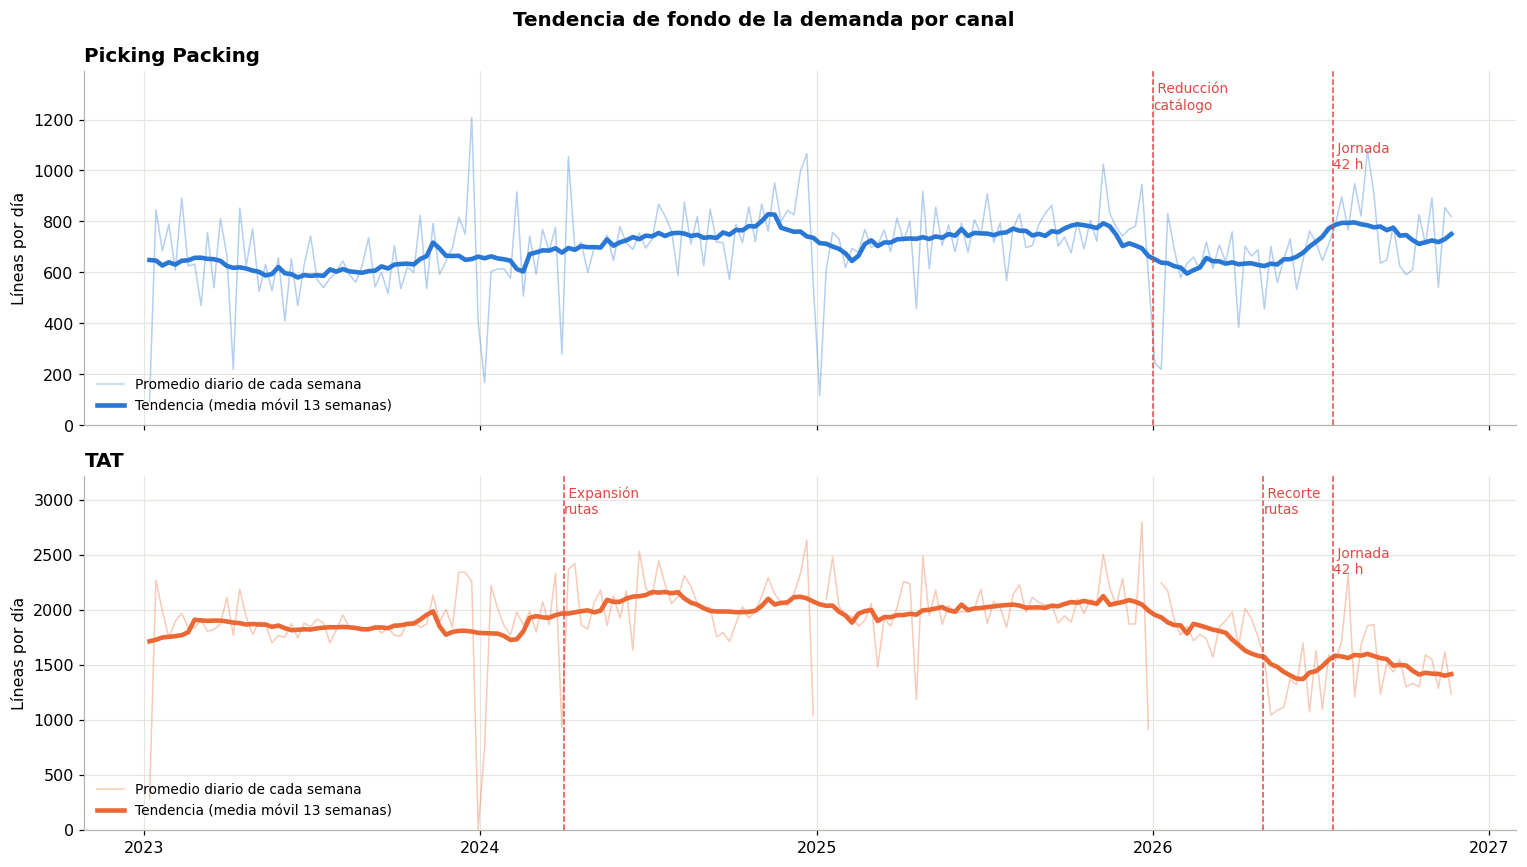

Variabilidad diaria vs. semanal:
              Picking Packing   TAT
CV diario %              45.7  30.8
CV semanal %             22.9  19.8


In [42]:
# ============================================
# CELDA 19c: Tendencia de fondo por canal (vista semanal)
# ============================================
# Eventos relevantes por canal: (fecha, etiqueta, altura relativa de la etiqueta)
EVENTOS = {
    'Picking Packing': [(pd.Timestamp('2026-01-01'), 'Reducción\ncatálogo', 0.97),
                        (INICIO_42H, 'Jornada\n42 h', 0.80)],
    'TAT': [(pd.Timestamp('2024-04-01'), 'Expansión\nrutas', 0.97),
            (pd.Timestamp('2026-05-01'), 'Recorte\nrutas', 0.97),
            (INICIO_42H, 'Jornada\n42 h', 0.80)]
}

fig, axs = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, canal in zip(axs, series.columns):
    sem = series[canal].resample('W-SAT').mean()          # 1 punto por semana
    tendencia = sem.rolling(13, center=True, min_periods=7).mean()

    ax.plot(sem.index, sem, color=COL[canal], lw=1, alpha=0.35, label='Promedio diario de cada semana')
    ax.plot(tendencia.index, tendencia, color=COL[canal], lw=3, label='Tendencia (media móvil 13 semanas)')

    ymax = sem.max() * 1.15
    ax.set_ylim(0, ymax)
    for f, txt, h in EVENTOS[canal]:
        ax.axvline(f, color=ROJO, ls='--', lw=1)
        ax.text(f, ymax * h, f' {txt}', color=ROJO, fontsize=9, va='top')

    ax.set_title(canal, loc='left'); ax.set_ylabel('Líneas por día')
    ax.legend(frameon=False, loc='lower left', fontsize=9)

axs[1].xaxis.set_major_locator(mdates.YearLocator())
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Tendencia de fondo de la demanda por canal', fontweight='bold', fontsize=13)
guardar('19_tendencia_semanal'); plt.show()

# ¿Cuánto ruido quita agregar por semana?
cv = pd.DataFrame({c: [series[c].std() / series[c].mean() * 100,
                       series[c].resample('W-SAT').mean().std() / series[c].resample('W-SAT').mean().mean() * 100]
                   for c in series}, index=['CV diario %', 'CV semanal %']).round(1)
print('Variabilidad diaria vs. semanal:'); print(cv)

### Conclusiones: tendencia de fondo de la demanda (vista semanal)

**Cómo se lee:** cada punto delgado es el promedio diario de una semana (elimina el efecto del día de la semana); la línea gruesa es la media móvil de 13 semanas (≈3 meses) y muestra la **tendencia de fondo**.

**La agregación semanal reduce el ruido a la mitad:**

| | Picking Packing | TAT |
|---|---|---|
| CV diario | 45.7% | 30.8% |
| CV semanal | 22.9% | 19.8% |

Por eso la vista semanal sirve para **entender** la tendencia, aunque el pronóstico sigue siendo **diario**.

**Picking Packing: estable, con ajustes de nivel**
- 2023 ≈ 600-650 líneas/día → 2024-2025 ≈ 750 (crecimiento y meseta).
- Inicio de 2026: baja a ≈ 620 (**reducción de catálogo**).
- Desde julio de 2026 sube a ≈ 790. **No es crecimiento de la demanda:** al salir el sábado del calendario (el día más bajo de PP, ≈356 líneas) y redistribuirse su volumen de lunes a viernes, **cada día operativo es más pesado**, aunque la semana mueva un volumen similar.

**TAT: dos escalones que explican toda su historia**
1. **Abril de 2024: escalón hacia arriba** (≈1,750 → ≈2,150 líneas/día). Coincide con la **expansión de rutas**: las ciudades atendidas al mes pasan de 48 a ≈65 *(hallazgo del análisis del equipo)*. Explica el crecimiento de 2024.
2. **2024-2025: meseta** en ≈2,000-2,100.
3. **2026: caída en dos etapas**
   - **Enero-abril:** pendiente suave (≈2,050 → ≈1,600), coherente con la **descontinuación de referencias**.
   - **Mayo: escalón hacia abajo** (→ ≈1,400) por el **recorte de rutas**.
4. **Julio-noviembre de 2026:** leve subida por la jornada de 42 h (mismo efecto de redistribución que en PP) y luego vuelve a ≈1,400. **No aparece el aumento habitual de noviembre.**


## 18. Anomalías de la serie diaria

**Diferencia con los outliers de la sección 4:** allí se analizó cada ciudad en un día; aquí se analiza el **total diario del canal** frente a lo **esperado** para ese día de la semana y esa época.

**Método** (base: análisis del equipo):
1. Descomposición **STL** de cada canal: serie = tendencia + estacionalidad semanal + residuo.
2. La STL se aplica **por tramo**, porque la semana operativa cambia: periodo 6 (lunes a sábado) hasta el 14-jul-2026 y periodo 5 (lunes a viernes) desde el 15-jul-2026.
3. **Anomalía** = día con |residuo estandarizado| > 3σ, calculado dentro de cada canal y cada tramo.
4. Cada anomalía se clasifica por **contexto de calendario**: fin/inicio de año, Semana Santa, día antes/después de festivo o sin causa de calendario.

Los días sin datos se interpolan **solo** para poder calcular la STL; no se usan como anomalías.

In [45]:
# ============================================
# CELDA 20b: STL por canal y por tramo + detección de anomalías
# ============================================
from statsmodels.tsa.seasonal import STL

# La semana operativa cambia de 6 a 5 días con la jornada de 42 h → STL por tramo
TRAMOS = [('Lun-Sáb (hasta 14-jul-2026)', None, INICIO_42H - pd.Timedelta(days=1), 6),
          ('Lun-Vie (desde 15-jul-2026)', INICIO_42H, None, 5)]

def stl_por_tramos(s):
    partes = []
    for nombre, ini, fin, periodo in TRAMOS:
        x = s.loc[ini:fin]
        x_interp = x.interpolate(limit_direction='both')          # interpolación SOLO para la STL
        r = STL(x_interp, period=periodo, seasonal=13,
                trend=31 if periodo == 6 else 21, robust=True).fit()
        partes.append(pd.DataFrame({'Lineas': x, 'Tendencia': r.trend, 'Estacional': r.seasonal,
                                    'Residuo': r.resid, 'Tramo': nombre}))
    return pd.concat(partes)

descomp = {canal: stl_por_tramos(series[canal]) for canal in series}

# --- Contexto de calendario de cada día ---
festivos_set = set(festivos)
from dateutil.easter import easter
# Jueves Santo = Domingo de Pascua − 3 días (no depende del idioma de la librería holidays)
jueves_santo = pd.to_datetime([easter(a) for a in range(2023, 2028)]) - pd.Timedelta(days=3)
print('Jueves Santo:', [d.date() for d in jueves_santo])
cal_lista = list(cal_op)
posicion = {d: i for i, d in enumerate(cal_lista)}

def contexto(f):
    if (f.month == 12 and f.day >= 19) or (f.month == 1 and f.day <= 17):
        return 'Fin / inicio de año'
    if any(js - pd.Timedelta(days=3) <= f <= js + pd.Timedelta(days=9) for js in jueves_santo):
        return 'Semana Santa (antes / después)'
    i = posicion.get(f)
    if i is not None and i > 0 and any(cal_lista[i-1] < x < f for x in festivos_set):
        return 'Día después de festivo'
    if i is not None and i < len(cal_lista) - 1 and any(f < x < cal_lista[i+1] for x in festivos_set):
        return 'Día antes de festivo'
    return 'Sin causa de calendario'

# --- Anomalía = |z| > 3 (z dentro de cada canal y cada tramo) ---
lista = []
for canal, d in descomp.items():
    d = d[d['Lineas'].notna()].copy()
    d['Esperado'] = d['Tendencia'] + d['Estacional']
    d['z'] = d.groupby('Tramo')['Residuo'].transform(lambda r: (r - r.mean()) / r.std())
    d['Canal'] = canal
    lista.append(d[d['z'].abs() > 3])

anom = pd.concat(lista)
anom['Día'] = anom.index.dayofweek.map(dict(enumerate(DIAS)))
anom['Tipo'] = np.where(anom['z'] < 0, 'Bajo', 'Alto')
anom['Contexto'] = [contexto(f) for f in anom.index]
anom = anom.reset_index()

for canal in series:
    n = (anom['Canal'] == canal).sum()
    print(f'{canal}: {n} anomalías ({n / series[canal].notna().sum():.1%} de los días con datos)')
print('\nAnomalías por contexto de calendario:')
print(pd.crosstab([anom['Canal'], anom['Contexto']], anom['Tipo']))
print('\nDetalle:')
print(anom.sort_values(['Canal', 'Fecha'])
          [['Canal', 'Fecha', 'Día', 'Lineas', 'Esperado', 'z', 'Tipo', 'Contexto']]
          .round({'Lineas': 0, 'Esperado': 0, 'z': 1}).to_string(index=False))

Jueves Santo: [datetime.date(2023, 4, 6), datetime.date(2024, 3, 28), datetime.date(2025, 4, 17), datetime.date(2026, 4, 2), datetime.date(2027, 3, 25)]
Picking Packing: 16 anomalías (1.4% de los días con datos)
TAT: 32 anomalías (2.9% de los días con datos)

Anomalías por contexto de calendario:
Tipo                                            Alto  Bajo
Canal           Contexto                                  
Picking Packing Día después de festivo             1     0
                Fin / inicio de año                6     0
                Semana Santa (antes / después)     5     1
                Sin causa de calendario            1     2
TAT             Día después de festivo             0     2
                Fin / inicio de año                4     8
                Semana Santa (antes / después)     2     6
                Sin causa de calendario            5     5

Detalle:
          Canal      Fecha       Día  Lineas  Esperado    z Tipo                       Contexto
Pickin

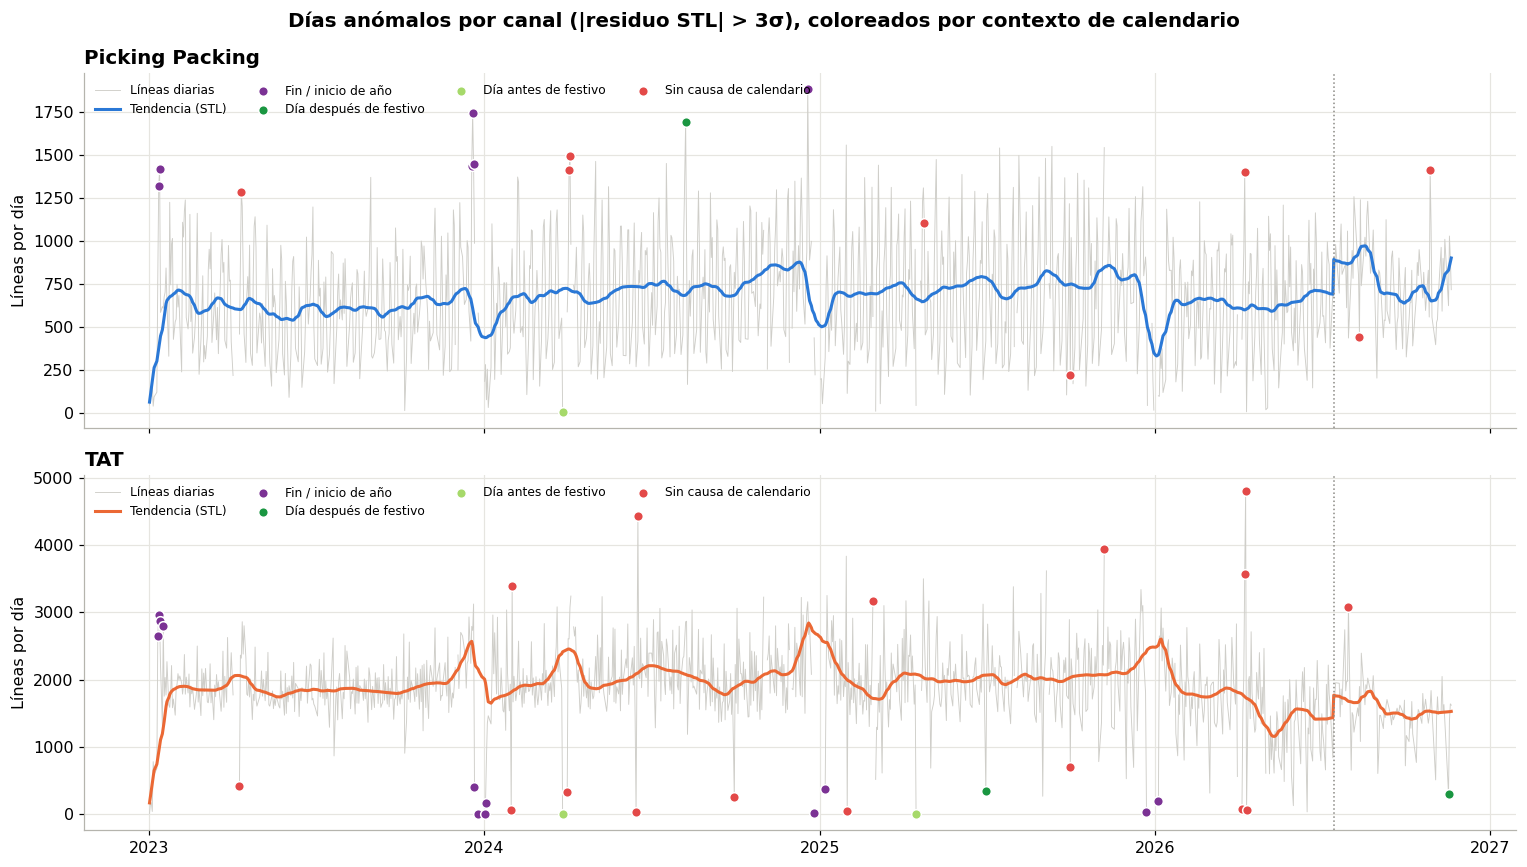

In [44]:
# ============================================
# CELDA 20c: Gráfica de anomalías por canal
# ============================================
colores_ctx = {'Fin / inicio de año': '#7b3294', 'Semana Santa (antes / después)': '#e66101',
               'Día después de festivo': '#1a9641', 'Día antes de festivo': '#a6d96a',
               'Sin causa de calendario': ROJO}

fig, axs = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, canal in zip(axs, series.columns):
    d = descomp[canal]
    ax.plot(d.index, d['Lineas'], color='#cfcec9', lw=0.6, label='Líneas diarias')
    ax.plot(d.index, d['Tendencia'], color=COL[canal], lw=2, label='Tendencia (STL)')
    a = anom[anom['Canal'] == canal]
    for ctx, color in colores_ctx.items():
        sub = a[a['Contexto'] == ctx]
        if len(sub):
            ax.scatter(sub['Fecha'], sub['Lineas'], color=color, s=40, zorder=3,
                       edgecolor='white', linewidth=1, label=ctx)
    ax.axvline(INICIO_42H, color=GRIS, ls=':', lw=1)
    ax.set_title(canal, loc='left'); ax.set_ylabel('Líneas por día')
    ax.legend(frameon=False, fontsize=8, ncol=4, loc='upper left')

axs[1].xaxis.set_major_locator(mdates.YearLocator())
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Días anómalos por canal (|residuo STL| > 3σ), coloreados por contexto de calendario',
             fontweight='bold', fontsize=13)
guardar('20_anomalias'); plt.show()

### Conclusiones: anomalías de la serie diaria

| Canal | Anomalías | % de días | Altas | Bajas |
|---|---|---|---|---|
| Picking Packing | 16 | 1.4% | 13 | 3 |
| TAT | 32 | 2.9% | 11 | 21 |

**1. Tres de cada cuatro anomalías tienen causa de calendario** (35 de 48):

| Contexto | Qué pasa | Ejemplos |
|---|---|---|
| **Fin / inicio de año** | TAT casi se detiene entre el 22-dic y el 7-ene (días con 2 a 411 líneas). PP **acumula** trabajo antes del cierre (19-21 de diciembre, hasta 1,884 líneas) y en la **reactivación** de enero. | 26-dic-2023 (9 líneas TAT), 20-dic-2023 (1,747 PP) |
| **Semana Santa** | El miércoles santo casi no se opera (7 líneas PP, 1 en TAT en 2024) y la semana **siguiente** concentra el trabajo represado. | 10-abr-2026: 4,796 líneas en TAT, el día más alto de la serie |
| **Día después de festivo** | En TAT, el martes después de un lunes festivo sale **bajo**, no alto. | 1-jul-2025 (348), 17-nov-2026 (307) |

**2. Los dos canales reaccionan distinto a los cierres:**
- **Picking Packing anticipa:** sus anomalías son casi todas **altas** (13 de 16). Los mayoristas concentran pedidos antes de los cierres.
- **TAT se detiene:** sus anomalías son mayoritariamente **bajas** (21 de 32). Las tiendas dejan de pedir en los cierres.

**3. Anomalías sin causa de calendario (13): por validar con la operación**
- **31 de enero, dos años seguidos en TAT** (68 líneas en 2024 y 54 en 2025): posible cierre o inventario anual.
- **1 de octubre de 2025:** cae en **ambos canales** el mismo día (225 PP y 705 TAT): posible evento operativo (sistema, inventario).
- **15 y 17 de junio de 2024 en TAT:** sábado casi sin operación (37) y lunes récord (4,435): trabajo **trasladado** del sábado al lunes.

**Tratamiento:**
1. **No se eliminan.** Las de calendario se repiten cada año; el modelo debe aprenderlas con variables de eventos:
   - `fin_de_anio` (19-dic a 17-ene), `semana_santa` y `semana_post_semana_santa`.
   - `dia_antes_festivo` y `dia_despues_festivo`.
2. Las de **causa operativa** (inventarios, fallas, traslados) no son demanda real: si se confirman, se marcan con una indicadora o se excluyen del entrenamiento (por ejemplo, poner `NaN` en Prophet).
3. El efecto del **día después de festivo en TAT es negativo**, al contrario de lo que suele suponerse: es mejor que el modelo lo aprenda de los datos que fijar el signo a mano.

## 19. Descomposición STL: fuerza de cada componente

Serie = **tendencia** + **estacionalidad semanal** + **residuo** (STL por canal y por tramo; ver sección 18).

**Fuerza de un componente** (Hyndman & Athanasopoulos): `F = max(0, 1 − Var(residuo) / Var(componente + residuo))`
- 0 = el componente no explica nada frente al ruido · 0.3-0.6 = moderado · > 0.6 = fuerte.
- Indica **qué tan predecible** es la serie con cada componente, y por tanto qué tanto error diario esperar.

*Base: medida de fuerza del análisis del equipo, ahora calculada por canal y por tramo.*

          Canal                       Tramo  Días  Fuerza tendencia  Fuerza estacionalidad semanal
Picking Packing Lun-Sáb (hasta 14-jul-2026)  1045              0.15                           0.42
Picking Packing Lun-Vie (desde 15-jul-2026)    87              0.19                           0.26
            TAT Lun-Sáb (hasta 14-jul-2026)  1045              0.00                           0.10
            TAT Lun-Vie (desde 15-jul-2026)    87              0.16                           0.01

(0 = nula · 0.3-0.6 = moderada · > 0.6 = fuerte)

Efecto promedio de cada día (componente estacional de la STL, en líneas):

Picking Packing
Dia                          Lunes  Martes  Miércoles  Jueves  Viernes  Sábado
Tramo                                                                         
Lun-Sáb (hasta 14-jul-2026) -151.0   -17.0      111.0   174.0     34.0  -172.0
Lun-Vie (desde 15-jul-2026) -113.0   -55.0       23.0   102.0      7.0     NaN

TAT
Dia                          Lunes  Martes

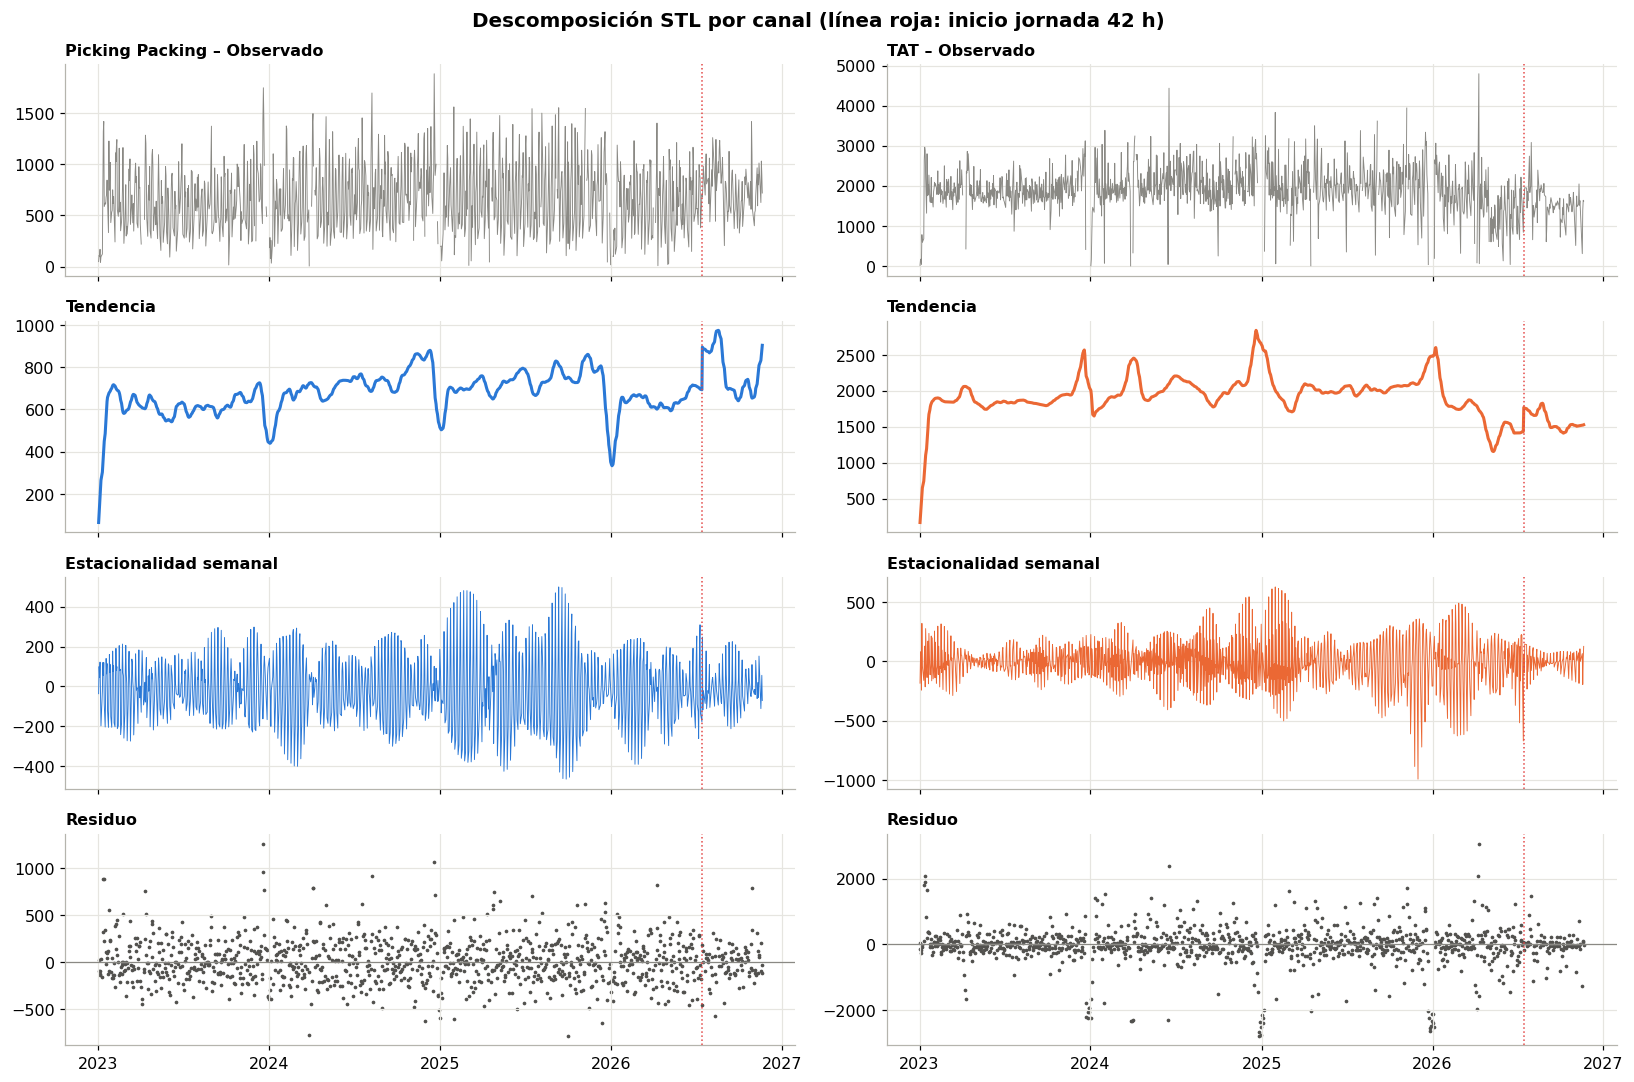

In [46]:
# ============================================
# CELDA 21b: Fuerza de tendencia y estacionalidad semanal por canal y tramo
# ============================================
def fuerza(d):
    v = lambda x: np.nanvar(x)
    ft = max(0, 1 - v(d['Residuo']) / v(d['Tendencia'] + d['Residuo']))
    fe = max(0, 1 - v(d['Residuo']) / v(d['Estacional'] + d['Residuo']))
    return ft, fe

filas = []
for canal, d in descomp.items():
    for tramo, dt in d.groupby('Tramo', sort=False):
        ft, fe = fuerza(dt)
        filas.append({'Canal': canal, 'Tramo': tramo, 'Días': len(dt),
                      'Fuerza tendencia': round(ft, 2),
                      'Fuerza estacionalidad semanal': round(fe, 2)})
print(pd.DataFrame(filas).to_string(index=False))
print('\n(0 = nula · 0.3-0.6 = moderada · > 0.6 = fuerte)')

# Patrón semanal que capturó la STL en cada tramo (efecto promedio de cada día, en líneas)
print('\nEfecto promedio de cada día (componente estacional de la STL, en líneas):')
for canal, d in descomp.items():
    tabla = (d.assign(Dia=pd.Categorical(d.index.dayofweek.map(dict(enumerate(DIAS))), DIAS))
               .groupby(['Tramo', 'Dia'], sort=False, observed=True)['Estacional'].mean()
               .unstack('Dia').round(0))
    print(f'\n{canal}'); print(tabla.to_string())

# Gráfica: componentes de la STL por canal
fig, axs = plt.subplots(4, 2, figsize=(15, 10), sharex=True)
for j, (canal, d) in enumerate(descomp.items()):
    comps = [('Lineas', 'Observado', GRIS), ('Tendencia', 'Tendencia', COL[canal]),
             ('Estacional', 'Estacionalidad semanal', COL[canal]), ('Residuo', 'Residuo', '#52514e')]
    for i, (col, titulo, color) in enumerate(comps):
        ax = axs[i, j]
        if col == 'Residuo':
            ax.scatter(d.index, d[col], s=2, color=color); ax.axhline(0, color=GRIS, lw=0.8)
        else:
            ax.plot(d.index, d[col], color=color, lw=2 if col == 'Tendencia' else 0.6)
        ax.axvline(INICIO_42H, color=ROJO, ls=':', lw=1)
        ax.set_title(f'{canal} – {titulo}' if i == 0 else titulo, loc='left', fontsize=10.5)
for ax in axs[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Descomposición STL por canal (línea roja: inicio jornada 42 h)', fontweight='bold', fontsize=13)
guardar('21_descomposicion_stl'); plt.show()

### Conclusiones: fuerza de los componentes de la serie

| Canal | Tramo | Días | Fuerza tendencia | Fuerza estacionalidad semanal |
|---|---|---|---|---|
| Picking Packing | Lun-Sáb (hasta 14-jul-2026) | 1,045 | 0.15 | **0.42** (moderada) |
| Picking Packing | Lun-Vie (desde 15-jul-2026) | 87 | 0.19 | 0.26 |
| TAT | Lun-Sáb (hasta 14-jul-2026) | 1,045 | 0.00 | **0.10** (débil) |
| TAT | Lun-Vie (desde 15-jul-2026) | 87 | 0.16 | **0.01** (nula) |

Efecto promedio de cada día según la STL (líneas sobre o bajo el nivel de la semana):

| | Lun | Mar | Mié | Jue | Vie | Sáb |
|---|---|---|---|---|---|---|
| PP – antes de jornada 42 h | -151 | -17 | +111 | **+174** | +34 | -172 |
| PP – desde jornada 42 h | -113 | -55 | +23 | **+102** | +7 | — |
| TAT – antes de jornada 42 h | **-169** | -36 | -1 | **+162** | 0 | +14 |
| TAT – desde jornada 42 h | **-8** | -1 | -20 | +42 | -8 | — |

**1. Los dos canales son muy distintos de predecir**
- **Picking Packing tiene un patrón semanal moderado (0.42):** el día de la semana explica una parte importante de la variación (jueves +174, sábado -172 líneas). Es su principal variable explicativa.
- **TAT casi no tiene patrón semanal (0.10)**, aunque el jueves es alto y el lunes bajo en promedio: el ruido diario es mucho mayor que esas diferencias.

**2. La jornada de 42 h cambió el patrón semanal**
- En **TAT el patrón semanal prácticamente desaparece (0.01):** el lunes pasa de -169 a **-8** líneas porque absorbe el volumen del sábado (sección 17).
- En **Picking Packing se suaviza** (0.42 → 0.26): el jueves sigue siendo el pico, pero con menos diferencia frente a los demás días.
- ⚠️ El tramo nuevo tiene solo 87 días (~17 semanas): estos valores son todavía poco estables.

**3. La tendencia es débil día a día, pero sus cambios son grandes**
- Una fuerza de tendencia baja (0.00-0.19) **no significa que la tendencia no importe**: sus escalones (expansión de 2024, recorte de 2026) son grandes. Significa que el **ruido diario es mucho mayor** que el movimiento de la tendencia de una semana a otra.

**Implicaciones para el modelo:**
1. Gran parte de la variación diaria queda en el **residuo** → se debe esperar un **error diario relativamente alto**, sobre todo en TAT. Esto se declara como expectativa realista desde el inicio.
2. **Picking Packing:** el **día de la semana** es la variable clave.
3. **TAT:** lo explicable vendrá sobre todo del **nivel** (regímenes de 2024 y 2026) y de los **eventos de calendario** (cierres de año, Semana Santa, festivos), más que del día de la semana.
4. El patrón semanal del modelo debe ser el del **régimen actual** (jornada de 42 h), no el de 2023-2025.
5. Para **planear personal**, el pronóstico **semanal** será más preciso que el diario (el CV baja a la mitad al agregar por semana, sección 17). Se reportarán ambos.

## 20. Estacionariedad (ADF + KPSS) y quiebres estructurales

- **ADF** – H0: la serie tiene raíz unitaria (no estacionaria). p < 0.05 → estacionaria.
- **KPSS** – H0: la serie es estacionaria. p < 0.05 → no estacionaria.
- Si ADF dice "estacionaria" y KPSS dice "no" → **resultado mixto**: no hay raíz unitaria, pero el **nivel medio cambia** (quiebres).
- **Zivot-Andrews** – prueba ADF que permite **un quiebre estructural** en el nivel y **estima la fecha** del quiebre. Sirve para validar con un método estadístico las fechas de los cambios operativos.

Se aplica por canal sobre el calendario operativo, a la serie diaria y a la semanal, en nivel y diferenciada.

*Base: pruebas ADF + KPSS del análisis del equipo, ahora por canal; se agrega Zivot-Andrews.*

In [47]:
# ============================================
# CELDA 22b: Estacionariedad por canal (ADF + KPSS)
# ============================================
from statsmodels.tsa.stattools import adfuller, kpss

def pruebas(x, canal, nombre):
    x = x.dropna()
    adf = adfuller(x, autolag='AIC')
    kp = kpss(x, regression='c', nlags='auto')
    adf_ok, kpss_ok = adf[1] < 0.05, kp[1] >= 0.05
    veredicto = ('Estacionaria' if adf_ok and kpss_ok else
                 'No estacionaria' if not adf_ok and not kpss_ok else
                 'Mixto: sin raíz unitaria, pero con cambios de nivel' if adf_ok else 'Mixto')
    return {'Canal': canal, 'Serie': nombre, 'n': len(x),
            'ADF p-valor': round(adf[1], 4), 'KPSS p-valor': round(kp[1], 3), 'Veredicto': veredicto}

filas = []
for canal in series:
    s = series[canal].interpolate(limit_direction='both')        # serie operativa completa
    s1 = s.loc[:INICIO_42H - pd.Timedelta(days=1)]               # tramo Lun-Sáb (periodo 6)
    sem = series[canal].resample('W-SAT').mean().interpolate()   # promedio diario semanal
    filas += [pruebas(s, canal, 'Diaria – nivel'),
              pruebas(s.diff(), canal, 'Diaria – 1ª diferencia'),
              pruebas(s1.diff(6), canal, 'Diaria – dif. estacional (6), tramo Lun-Sáb'),
              pruebas(sem, canal, 'Semanal – nivel'),
              pruebas(sem.diff(), canal, 'Semanal – 1ª diferencia')]

print(pd.DataFrame(filas).to_string(index=False))
print('\nADF  H0: raíz unitaria (no estacionaria) → p < 0.05 = estacionaria')
print('KPSS H0: estacionaria                    → p < 0.05 = NO estacionaria')
print('KPSS reporta p-valores acotados entre 0.01 y 0.10 (0.01 = "≤ 0.01", 0.10 = "≥ 0.10")')

/tmp/ipykernel_623/130530372.py:9: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_623/130530372.py:9: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_623/130530372.py:9: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_623/130530372.py:9: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_623/130530372.py:9: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-va

          Canal                                       Serie    n  ADF p-valor  KPSS p-valor                                           Veredicto
Picking Packing                              Diaria – nivel 1132       0.0000         0.010 Mixto: sin raíz unitaria, pero con cambios de nivel
Picking Packing                      Diaria – 1ª diferencia 1131       0.0000         0.100                                        Estacionaria
Picking Packing Diaria – dif. estacional (6), tramo Lun-Sáb 1039       0.0000         0.100                                        Estacionaria
Picking Packing                             Semanal – nivel  203       0.0013         0.010 Mixto: sin raíz unitaria, pero con cambios de nivel
Picking Packing                     Semanal – 1ª diferencia  202       0.0000         0.100                                        Estacionaria
            TAT                              Diaria – nivel 1132       0.0001         0.010 Mixto: sin raíz unitaria, pero con cambios d

/tmp/ipykernel_623/130530372.py:9: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.



In [48]:
# ============================================
# CELDA 22c: Zivot-Andrews – prueba de raíz unitaria con un quiebre estructural
# ============================================
from statsmodels.tsa.stattools import zivot_andrews

filas = []
for canal in series:
    for nombre, x in [('Diaria', series[canal].interpolate(limit_direction='both')),
                      ('Semanal', series[canal].resample('W-SAT').mean().interpolate())]:
        za = zivot_andrews(x, regression='c', autolag='AIC')
        filas.append({'Canal': canal, 'Serie': nombre, 'Estadístico': round(za[0], 2),
                      'p-valor': round(za[1], 4),
                      'Fecha estimada del quiebre': x.index[za[4]].date(),
                      'Veredicto': 'Estacionaria con 1 quiebre de nivel' if za[1] < 0.05 else 'Raíz unitaria'})
print(pd.DataFrame(filas).to_string(index=False))

          Canal   Serie  Estadístico  p-valor Fecha estimada del quiebre                           Veredicto
Picking Packing  Diaria        -6.52   0.0003                 2025-12-22 Estacionaria con 1 quiebre de nivel
Picking Packing Semanal        -6.26   0.0006                 2025-12-20 Estacionaria con 1 quiebre de nivel
            TAT  Diaria        -7.22   0.0000                 2025-12-20 Estacionaria con 1 quiebre de nivel
            TAT Semanal        -5.36   0.0071                 2026-04-25 Estacionaria con 1 quiebre de nivel


### Conclusiones: estacionariedad y quiebres estructurales

**1. ADF + KPSS**

| Serie | Picking Packing | TAT |
|---|---|---|
| Diaria – nivel | Mixto (ADF p<0.001 · KPSS p≤0.01) | Mixto (ADF p<0.001 · KPSS p≤0.01) |
| Diaria – 1ª diferencia | ✅ Estacionaria | ✅ Estacionaria |
| Diaria – dif. estacional (6) | ✅ Estacionaria | ✅ Estacionaria |
| Semanal – nivel | Mixto (ADF p=0.001 · KPSS p≤0.01) | ❌ No estacionaria (ADF p=0.07 · KPSS p=0.017) |
| Semanal – 1ª diferencia | ✅ Estacionaria | ✅ Estacionaria |

- **En nivel, la serie no es estacionaria en sentido estricto:** no tiene raíz unitaria (no "deriva" al azar), pero su **nivel medio cambia** en momentos concretos.
- **TAT semanal** es la serie menos estacionaria: es donde más pesa el escalón de 2026.
- **Con una sola diferenciación** (diaria, estacional o semanal), ambas pruebas coinciden en **estacionaria** en los dos canales.

**2. Zivot-Andrews: los datos ubican solos los quiebres**

| Canal | Serie | p-valor | Quiebre estimado | Decisión de negocio asociada |
|---|---|---|---|---|
| Picking Packing | Diaria | 0.0003 | **22-dic-2025** | Reducción de catálogo (inicio de 2026) |
| Picking Packing | Semanal | 0.0006 | **20-dic-2025** | Reducción de catálogo (inicio de 2026) |
| TAT | Diaria | <0.0001 | 20-dic-2025 | Reducción de catálogo (inicio de 2026) |
| TAT | Semanal | 0.0071 | **25-abr-2026** | Recorte de rutas (mayo de 2026) |

- Al permitir **un quiebre de nivel**, las cuatro series resultan **estacionarias alrededor de ese quiebre**: lo que la hace "no estacionaria" es el escalón, no una tendencia aleatoria.
- La prueba **no conoce la operación** y aun así ubica los quiebres en las fechas de las decisiones de negocio. Es una **validación estadística independiente** de lo confirmado con la operación.
- En TAT, la serie semanal (menos ruidosa) detecta el **recorte de rutas**; la diaria detecta el inicio de la reducción de catálogo.
- *Limitación:* Zivot-Andrews detecta **solo el quiebre más fuerte**. La serie tiene varios (expansión TAT abr-2024, catálogo dic-2025/ene-2026, rutas may-2026, jornada 42 h jul-2026).



## 21. Autocorrelación (ACF / PACF) y selección de rezagos

- **ACF:** correlación de la serie con ella misma desplazada *k* días. Picos cada 6 rezagos = patrón semanal (tramo lunes a sábado).
- **PACF:** correlación con el rezago *k* quitando el efecto de los rezagos intermedios.

**Regla de oro (horizonte de 7 días):** el corte es el último día operativo de la semana y se pronostica la semana siguiente completa. El modelo solo puede usar información disponible en el corte → **rezagos ≥ 7 días calendario**. El "día anterior" (lag 1) **no** está disponible para todo el horizonte: usarlo sería *data leakage*.

**Por qué en días calendario y no en días operativos:** con la jornada de 42 h la semana operativa pasó de 6 a 5 días. "Hace 6 días operativos" ya no es el mismo día de la semana; **"hace 7 días calendario" sí lo es siempre**.

*Base: ACF/PACF del análisis del equipo, ahora por canal.*

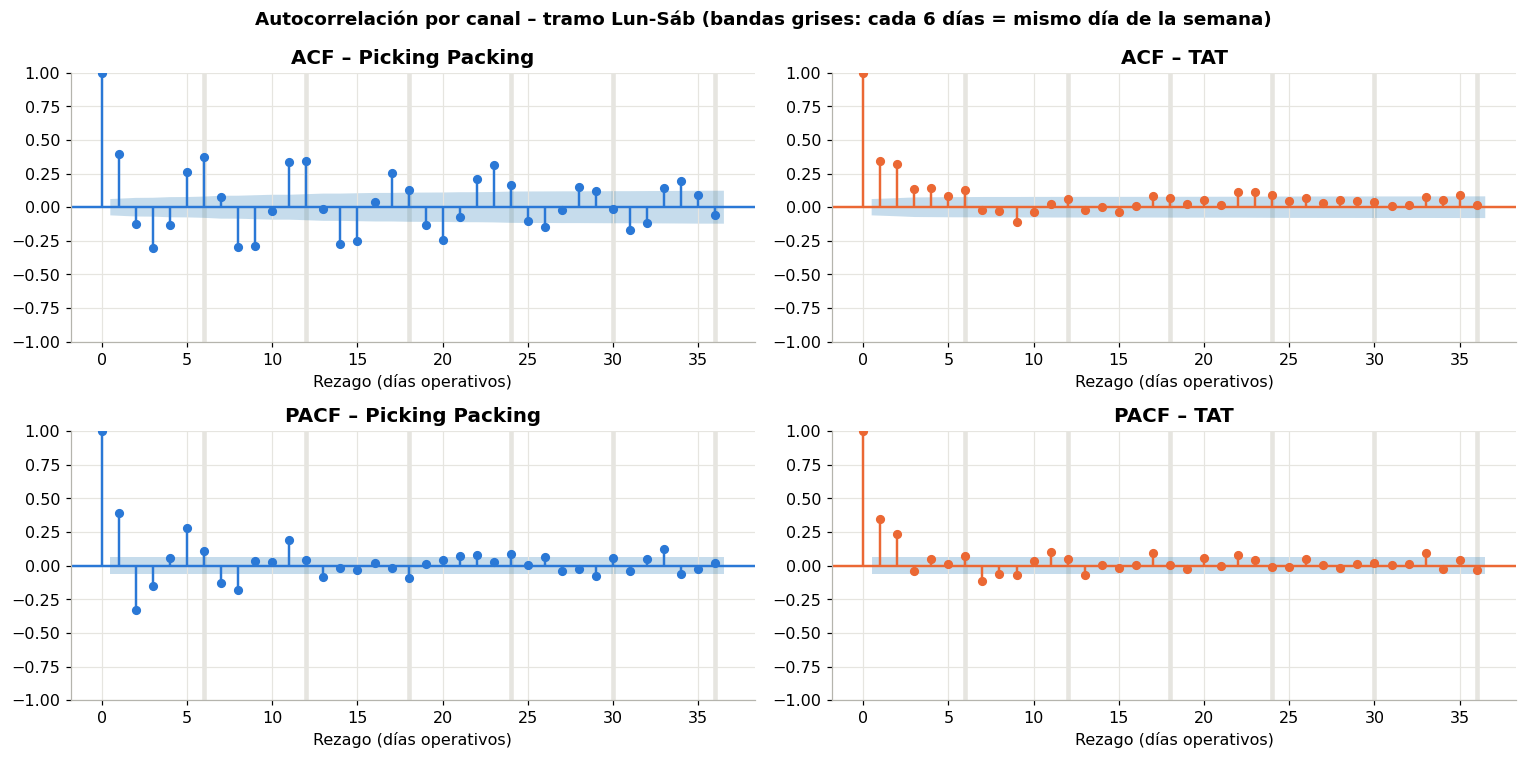

Picking Packing – ACF lag 1: 0.39 | lag 6 (mismo día semana pasada): 0.37 | lag 12: 0.34
TAT – ACF lag 1: 0.34 | lag 6 (mismo día semana pasada): 0.13 | lag 12: 0.06


In [49]:
# ============================================
# CELDA 23b: ACF y PACF por canal (tramo Lun-Sáb, índice en días operativos)
# ============================================
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf

tramo1 = slice(None, INICIO_42H - pd.Timedelta(days=1))
fig, axs = plt.subplots(2, 2, figsize=(14, 7))
for j, canal in enumerate(series.columns):
    x = series[canal].loc[tramo1].interpolate(limit_direction='both')
    plot_acf(x, lags=36, ax=axs[0, j], color=COL[canal], vlines_kwargs={'colors': COL[canal]})
    plot_pacf(x, lags=36, ax=axs[1, j], method='ywm', color=COL[canal], vlines_kwargs={'colors': COL[canal]})
    axs[0, j].set_title(f'ACF – {canal}'); axs[1, j].set_title(f'PACF – {canal}')
for ax in axs.flat:
    for k in range(6, 37, 6): ax.axvline(k, color='#e6e5e0', lw=3, zorder=0)
    ax.set_xlabel('Rezago (días operativos)')
fig.suptitle('Autocorrelación por canal – tramo Lun-Sáb (bandas grises: cada 6 días = mismo día de la semana)',
             fontweight='bold', fontsize=12)
guardar('23_acf_pacf'); plt.show()

for canal in series:
    x = series[canal].loc[tramo1].interpolate(limit_direction='both')
    a = acf(x, nlags=12)
    print(f'{canal} – ACF lag 1: {a[1]:.2f} | lag 6 (mismo día semana pasada): {a[6]:.2f} | lag 12: {a[12]:.2f}')

In [51]:
# ============================================
# CELDA 23c: Correlación con rezagos en DÍAS CALENDARIO (los que usará el modelo)
# ============================================
LAGS = [1, 7, 14, 21, 28, 364]
filas = []
for canal in series:
    cal_full = series[canal].asfreq('D')               # índice calendario (domingos/festivos = NaN)
    for tramo, ini, fin in [('Lun-Sáb (hasta 14-jul-2026)', None, INICIO_42H - pd.Timedelta(days=1)),
                            ('Lun-Vie (desde 15-jul-2026)', INICIO_42H, None)]:
        fila = {'Canal': canal, 'Tramo': tramo}
        y = cal_full.loc[ini:fin]
        for k in LAGS:
            par = pd.concat([y, cal_full.shift(k).loc[y.index]], axis=1).dropna()
            fila[f'lag {k}d'] = round(par.iloc[:, 0].corr(par.iloc[:, 1]), 2) if len(par) > 20 else np.nan
        # Promedio del mismo día en las últimas 4 semanas
        prom4 = pd.concat([cal_full.shift(k) for k in (7, 14, 21, 28)], axis=1).mean(axis=1)
        par = pd.concat([y, prom4.loc[y.index]], axis=1).dropna()
        fila['prom. 4 sem.'] = round(par.iloc[:, 0].corr(par.iloc[:, 1]), 2)
        filas.append(fila)

print(pd.DataFrame(filas).to_string(index=False))
print('\nlag 1d = día calendario anterior · lag 7d = mismo día de la semana pasada · lag 364d = mismo día del año pasado')

          Canal                       Tramo  lag 1d  lag 7d  lag 14d  lag 21d  lag 28d  lag 364d  prom. 4 sem.
Picking Packing Lun-Sáb (hasta 14-jul-2026)    0.24    0.45     0.53     0.42     0.55      0.57          0.61
Picking Packing Lun-Vie (desde 15-jul-2026)    0.15    0.35     0.37     0.25     0.37      0.20          0.43
            TAT Lun-Sáb (hasta 14-jul-2026)    0.15    0.21     0.31     0.30     0.32      0.28          0.39
            TAT Lun-Vie (desde 15-jul-2026)    0.28   -0.13     0.23     0.05     0.07      0.12          0.02

lag 1d = día calendario anterior · lag 7d = mismo día de la semana pasada · lag 364d = mismo día del año pasado


### Conclusiones: autocorrelación y selección de rezagos

**ACF / PACF (tramo lunes a sábado, índice en días operativos)**

| | Picking Packing | TAT |
|---|---|---|
| ACF | **Ola semanal** persistente: picos cada ~6 rezagos, valles negativos a 3 rezagos (jueves vs. lunes) | **Sin ola semanal**: solo lags 1-2 (~0.33); después, ruido |
| PACF | Lag 1 (+0.39), lag 2 (−0.33), lag 5 y 11; nada después de ~12 | Solo lags 1 (0.34) y 2 (0.23) |
| Lectura | Ritmo semanal claro: el día de la semana importa | Lo que predice a TAT es el **nivel reciente**, no el día de la semana |

- Los picos a veces caen en 5 y no en 6 porque los **festivos** acortan la semana en el índice de días operativos → los rezagos del modelo se definen en **días calendario** (7 días = siempre el mismo día de la semana).

**Rezagos en días calendario (correlación con el valor del día):**

| Canal / tramo | lag 1d | lag 7d | lag 14d | lag 28d | lag 364d | Prom. 4 semanas |
|---|---|---|---|---|---|---|
| PP – Lun-Sáb | 0.24 | 0.45 | 0.53 | 0.55 | 0.57 | **0.61** |
| PP – Lun-Vie (42 h) | 0.15 | 0.35 | 0.37 | 0.37 | 0.20 | **0.43** |
| TAT – Lun-Sáb | 0.15 | 0.21 | 0.31 | 0.32 | 0.28 | **0.39** |
| TAT – Lun-Vie (42 h) | 0.28 | −0.13 | 0.23 | 0.07 | 0.12 | 0.02 |

**Hallazgos:**
1. **El mejor predictor disponible es el promedio del mismo día en las últimas 4 semanas** (0.61 en PP): promediar reduce el ruido de una sola semana.
2. **En PP, los lags de 14 y 28 días (0.53-0.55) superan a los de 7 y 21 (0.42-0.45):** posible patrón **quincenal** de rutas (ciudades que salen en semanas alternas). *Hipótesis por validar con la operación.*
3. **El mismo día del año anterior (lag 364)** aporta en PP (0.57): confirma la estacionalidad anual.
4. **En TAT bajo la jornada de 42 h las correlaciones casi desaparecen:** el nivel es estable y la variación diaria es ruido sin patrón. Su mejor predictor será el **nivel reciente** más los **eventos de calendario**; se comprobará con métricas de error en el modelado.

**Decisiones para el modelo (evitando data leakage):**
- ❌ **No usar lag 1 ni lag 2**: no están disponibles para todo el horizonte de 7 días.
- ✅ **Rezagos válidos:** `lag_7`, `lag_14`, `lag_21`, `lag_28`, `prom_4_semanas` (mismo día) y `lag_364`.
- ✅ **Nivel reciente al corte:** promedio de los últimos 5-10 días operativos antes del corte. Reemplaza la información de lags 1-2 sin hacer trampa.
- **SARIMA:** la PACF de PP sugiere términos AR de orden bajo más un componente estacional; para el régimen actual, el periodo es 5.

# PARTE 3 — Productividad y capacidad

## 22. Productividad de picking por canal

**Fuente:** segunda extracción SQL desde `txpicking` (concepto 2), con una fila por **Usuario × Día × Canal**: líneas pickeadas, hora de la primera y de la última línea, y minutos entre ambas.

**¿Por qué una segunda extracción?** En el dataset principal, `Usuarios_Picking` cuenta operarios **por ciudad**. Un mismo operario pickea para varias ciudades el mismo día, así que **sumar esa columna cuenta varias veces a la misma persona** (en PP daba ≈40 "usuarios" diarios cuando en realidad son ≈7). Este dataset resuelve el problema de granularidad desde la fuente.

**Métricas:**
- **Operarios/día:** usuarios distintos que pickearon en el canal.
- **Líneas por operario por día** = líneas del canal ÷ operarios.
- **Líneas por hora activa** = líneas ÷ horas entre la primera y la última línea de cada operario.

⚠️ `Minutos_Activo` es una **aproximación**: incluye pausas intermedias y no incluye tareas fuera del picking.

In [52]:
# ============================================
# CELDA 24b: Carga y validación del dataset de productividad
# ============================================
prod = pd.read_csv('productividad_usuarios_picking.csv', sep=';', encoding='utf-8-sig')
prod['Fecha'] = pd.to_datetime(prod['Fecha'], dayfirst=True)
prod['Primera_Linea'] = pd.to_datetime(prod['Primera_Linea'])
prod['Ultima_Linea'] = pd.to_datetime(prod['Ultima_Linea'])
prod['Canal'] = prod['Canal'].map(CANALES)            # 'Picking Packing' / 'TAT'
prod['Horas_Activo'] = prod['Minutos_Activo'] / 60

print(f'Registros: {len(prod):,} (una fila = Usuario × Día × Canal) | Operarios distintos: {prod["Usuario"].nunique()}')
print(f'Rango: {prod["Fecha"].min().date()} a {prod["Fecha"].max().date()} | Nulos: {prod.isna().sum().sum()}')

# Validación cruzada: las líneas deben coincidir con el dataset principal
check = pd.concat([diario.stack().rename('Dataset principal'),
                   prod.groupby(['Fecha', 'Canal'])['Lineas'].sum().rename('Productividad')], axis=1).dropna()
print(f'Días-canal comparados: {len(check):,} | coinciden exactamente: {(check.iloc[:, 0] == check.iloc[:, 1]).mean():.1%}')

# Casos especiales
multi = prod.groupby(['Fecha', 'Usuario'])['Canal'].nunique()
print(f'\nOperario en ambos canales el mismo día: {(multi > 1).sum():,} casos ({(multi > 1).mean():.1%} de los usuario-día)')
print(f'Filas con 0 minutos (1 sola línea o líneas en el mismo minuto): {(prod["Minutos_Activo"] == 0).sum()}')
print(f'Filas con menos de 30 minutos de actividad: {(prod["Minutos_Activo"] < 30).sum():,} ({(prod["Minutos_Activo"] < 30).mean():.1%})')
print('\nHora de inicio de actividad (cantidad de usuario-día):')
print(prod['Primera_Linea'].dt.hour.value_counts().sort_index().to_string())

Registros: 16,810 (una fila = Usuario × Día × Canal) | Operarios distintos: 80
Rango: 2023-01-02 a 2026-11-20 | Nulos: 0
Días-canal comparados: 2,219 | coinciden exactamente: 100.0%

Operario en ambos canales el mismo día: 1,020 casos (6.5% de los usuario-día)
Filas con 0 minutos (1 sola línea o líneas en el mismo minuto): 244
Filas con menos de 30 minutos de actividad: 1,000 (5.9%)

Hora de inicio de actividad (cantidad de usuario-día):
Primera_Linea
4        4
5      368
6     4154
7     1612
8     2129
9     3987
10    2125
11     956
12     415
13     416
14     336
15     204
16      62
17      30
18       1
19       8
20       3


PRODUCTIVIDAD DIARIA POR CANAL (percentiles 25, 50 y 75)
Canal                 Picking Packing    TAT
Usuarios         25%              6.0    7.0
                 50%              7.0    8.0
                 75%              8.0    9.0
Lineas_x_Usuario 25%             63.6  198.2
                 50%             94.4  236.5
                 75%            126.0  285.1
Lineas_x_Hora    25%             13.0   43.0
                 50%             15.8   50.4
                 75%             18.9   59.8
Horas_x_Usuario  25%              4.5    3.9
                 50%              6.3    4.8
                 75%              7.8    5.7

MEDIANA POR DÍA DE LA SEMANA

Picking Packing
                 Lineas                   Usuarios              Lineas_x_Usuario             
Tramo     Antes de 42 h Jornada 42 h Antes de 42 h Jornada 42 h    Antes de 42 h Jornada 42 h
Dia                                                                                          
Lunes             432.0      

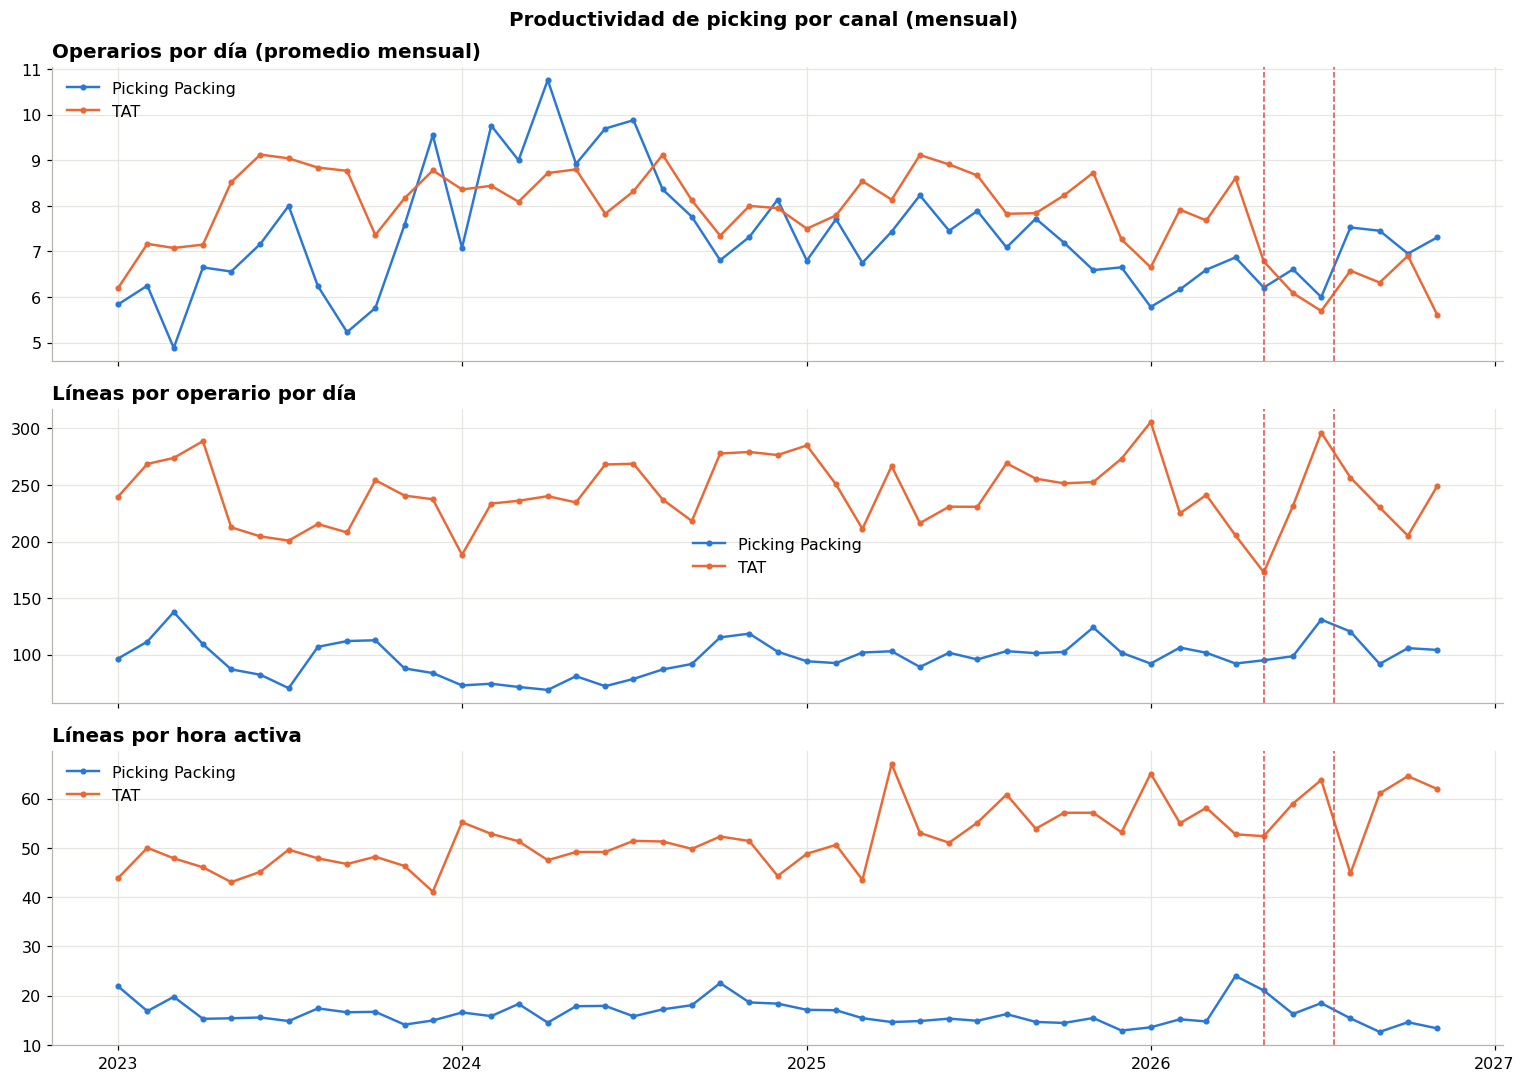

In [53]:
# ============================================
# CELDA 24c: Productividad diaria y mensual por canal
# ============================================
prod_dia = (prod.groupby(['Fecha', 'Canal'])
                .agg(Lineas=('Lineas', 'sum'), Usuarios=('Usuario', 'nunique'), Horas=('Horas_Activo', 'sum'))
                .reset_index())
prod_dia = prod_dia[prod_dia['Fecha'].isin(cal_op)]                       # solo días operativos
prod_dia['Lineas_x_Usuario'] = prod_dia['Lineas'] / prod_dia['Usuarios']
prod_dia['Lineas_x_Hora'] = prod_dia['Lineas'] / prod_dia['Horas'].where(prod_dia['Horas'] > 0)
prod_dia['Horas_x_Usuario'] = prod_dia['Horas'] / prod_dia['Usuarios']
prod_dia['Tramo'] = np.where(prod_dia['Fecha'] >= INICIO_42H, 'Jornada 42 h', 'Antes de 42 h')
prod_dia['Dia'] = pd.Categorical(prod_dia['Fecha'].dt.dayofweek.map(dict(enumerate(DIAS))), DIAS)

# 1. Resumen por canal
cols = ['Usuarios', 'Lineas_x_Usuario', 'Lineas_x_Hora', 'Horas_x_Usuario']
print('PRODUCTIVIDAD DIARIA POR CANAL (percentiles 25, 50 y 75)')
print(prod_dia.groupby('Canal')[cols].describe(percentiles=[.25, .5, .75])
              .loc[:, (slice(None), ['25%', '50%', '75%'])].round(1).T.to_string())

# 2. Por día de la semana y tramo (mediana)
print('\nMEDIANA POR DÍA DE LA SEMANA')
for canal in series:
    t = (prod_dia[prod_dia['Canal'] == canal]
           .groupby(['Tramo', 'Dia'], observed=True)[['Lineas', 'Usuarios', 'Lineas_x_Usuario']].median()
           .round(0).unstack('Tramo'))
    print(f'\n{canal}'); print(t.to_string())

# 3. Por año
print('\nPROMEDIO POR AÑO')
print(prod_dia.groupby(['Canal', prod_dia['Fecha'].dt.year.rename('Año')])[cols].mean().round(1).to_string())

# 4. Gráfica mensual
prod_mes = (prod_dia.assign(Mes=prod_dia['Fecha'].dt.to_period('M').dt.to_timestamp())
                    .groupby(['Mes', 'Canal'])[['Usuarios', 'Lineas_x_Usuario', 'Lineas_x_Hora']].mean().reset_index())
fig, axs = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for canal in series:
    m = prod_mes[prod_mes['Canal'] == canal]
    axs[0].plot(m['Mes'], m['Usuarios'], marker='o', ms=3, color=COL[canal], label=canal)
    axs[1].plot(m['Mes'], m['Lineas_x_Usuario'], marker='o', ms=3, color=COL[canal], label=canal)
    axs[2].plot(m['Mes'], m['Lineas_x_Hora'], marker='o', ms=3, color=COL[canal], label=canal)
for ax, t in zip(axs, ['Operarios por día (promedio mensual)', 'Líneas por operario por día', 'Líneas por hora activa']):
    ax.set_title(t, loc='left'); ax.legend(frameon=False)
    for f in [pd.Timestamp('2026-05-01'), INICIO_42H]: ax.axvline(f, color=ROJO, ls='--', lw=1)
axs[2].xaxis.set_major_locator(mdates.YearLocator())
axs[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Productividad de picking por canal (mensual)', fontweight='bold', fontsize=13)
guardar('24_productividad_mensual'); plt.show()

### Conclusiones: productividad de picking por canal

**Validación:** las líneas del dataset de productividad coinciden al **100%** con el dataset principal (2,219 días-canal). 80 operarios distintos; 6.5% de los usuario-día trabajan en ambos canales.

**1. Cifras base (mediana por día operativo)**

| | Picking Packing | TAT |
|---|---|---|
| Operarios por día | **7** (rango intercuartil 6-8) | **8** (7-9) |
| Líneas por operario por día | 94 (64-126) | 237 (198-285) |
| Líneas por hora activa | **16** (13-19) | **50** (43-60) |
| Horas activas por operario | 6.3 | 4.8 |

- **Una línea no pesa igual en ambos canales:** en TAT se pickean ≈3 veces más líneas por hora. Una línea TAT son pocas unidades para una tienda; una línea mayorista son muchas cajas. Para planear personal, **cada canal necesita su propia productividad de referencia**.

**2. Antes de la jornada de 42 h, la plantilla no seguía a la demanda diaria**

| Picking Packing (mediana) | Lun | Mar | Mié | Jue | Vie | Sáb |
|---|---|---|---|---|---|---|
| Líneas | 432 | 678 | 851 | **1,001** | 763 | 345 |
| Operarios | 7 | 7 | 7 | 7 | 8 | 6 |
| Líneas por operario | 57 | 94 | 118 | **133** | 99 | 53 |

- El jueves movía **2.3 veces** el volumen del lunes con **el mismo número de personas**: los lunes y sábados sobraba capacidad y los jueves la operación iba al límite. En TAT pasaba lo mismo (8 operarios siempre; el jueves +47% de líneas frente al lunes).

**3. Con la jornada de 42 h, el desbalance diario se reduce**
- **Picking Packing:** la carga por operario pasa a 90-121 líneas (antes 53-133). El lunes absorbe el sábado; el **jueves sigue siendo el día más exigente** (903 líneas, +37% frente al martes).
- **TAT:** baja de **8 a 6 operarios** por día y la carga queda **pareja** (237-254 líneas por operario todos los días), consistente con la desaparición de su patrón semanal (sección 19).

**4. Tendencia por año**
- **TAT mejora su velocidad:** de 46.5 a **58 líneas/hora** (2023 → 2026, +25%), con menos horas activas por operario (5.2 → 4.3). Posibles causas: menos ciudades y un catálogo más corto, que concentran el recorrido en bodega.
- **Picking Packing 2024:** más operarios (8.6) con **menos líneas por persona** (86): más personal no se tradujo en más volumen.

**Implicaciones:**
- La planeación de personal debe hacerse **por canal**, con su productividad propia (PP ≈ 16 líneas/h; TAT ≈ 50 líneas/h).
- En el régimen actual, la variación **día a día** es moderada (principalmente el jueves de PP); la variación relevante para dimensionar personal está **entre semanas** (festivos, Semana Santa, fin de año, temporada). Se cuantifica en la siguiente sección.
- ⚠️ *Limitación:* las horas activas son el tiempo entre la primera y la última línea; incluyen pausas y excluyen otras tareas.

## 23. Capacidad: de líneas pronosticadas a operarios necesarios

**Preguntas:**
1. Cuando el volumen sube, ¿la operación agrega **personas** o agrega **horas**?
2. Con la productividad actual, ¿cuántos operarios se necesitan para un volumen dado?
3. ¿Qué tanto varía hoy la carga por operario?

**Fórmula de capacidad (régimen actual, jornada 42 h):**
> Operarios necesarios = Líneas ÷ (Líneas por hora por operario × Horas activas por operario)

Los parámetros son las **medianas del régimen actual** (desde el 15-jul-2026), porque es el escenario en el que se usará el modelo.

CORRELACIÓN DIARIA CON LAS LÍNEAS
  Picking Packing  vs operarios: 0.35 | vs horas-operario: 0.82
  TAT              vs operarios: 0.41 | vs horas-operario: 0.74

MEDIANAS SEGÚN EL NÚMERO DE OPERARIOS DEL DÍA (solo grupos con ≥ 20 días)

Picking Packing
Usuarios             4      5      6      7      8      9      10     11
Dias               34.0   94.0  218.0  259.0  230.0  119.0   74.0   36.0
Lineas            345.5  468.5  647.5  706.0  787.0  756.0  781.5  865.5
Lineas_x_Usuario   86.4   93.7  107.9  100.9   98.4   84.0   78.2   78.7
Horas_x_Usuario     5.2    6.6    7.2    6.8    6.7    5.8    5.2    4.8
Lineas_x_Hora      19.1   17.1   16.2   15.6   15.0   16.3   15.1   14.7

TAT
Usuarios              5       6       7       8       9       10      11
Dias                33.0    98.0   247.0   323.0   248.0    93.0    20.0
Lineas            1492.0  1643.5  1841.0  1942.0  1915.5  2024.0  2026.5
Lineas_x_Usuario   298.4   273.9   263.0   242.8   212.8   202.4   184.2
Horas_x_Usu

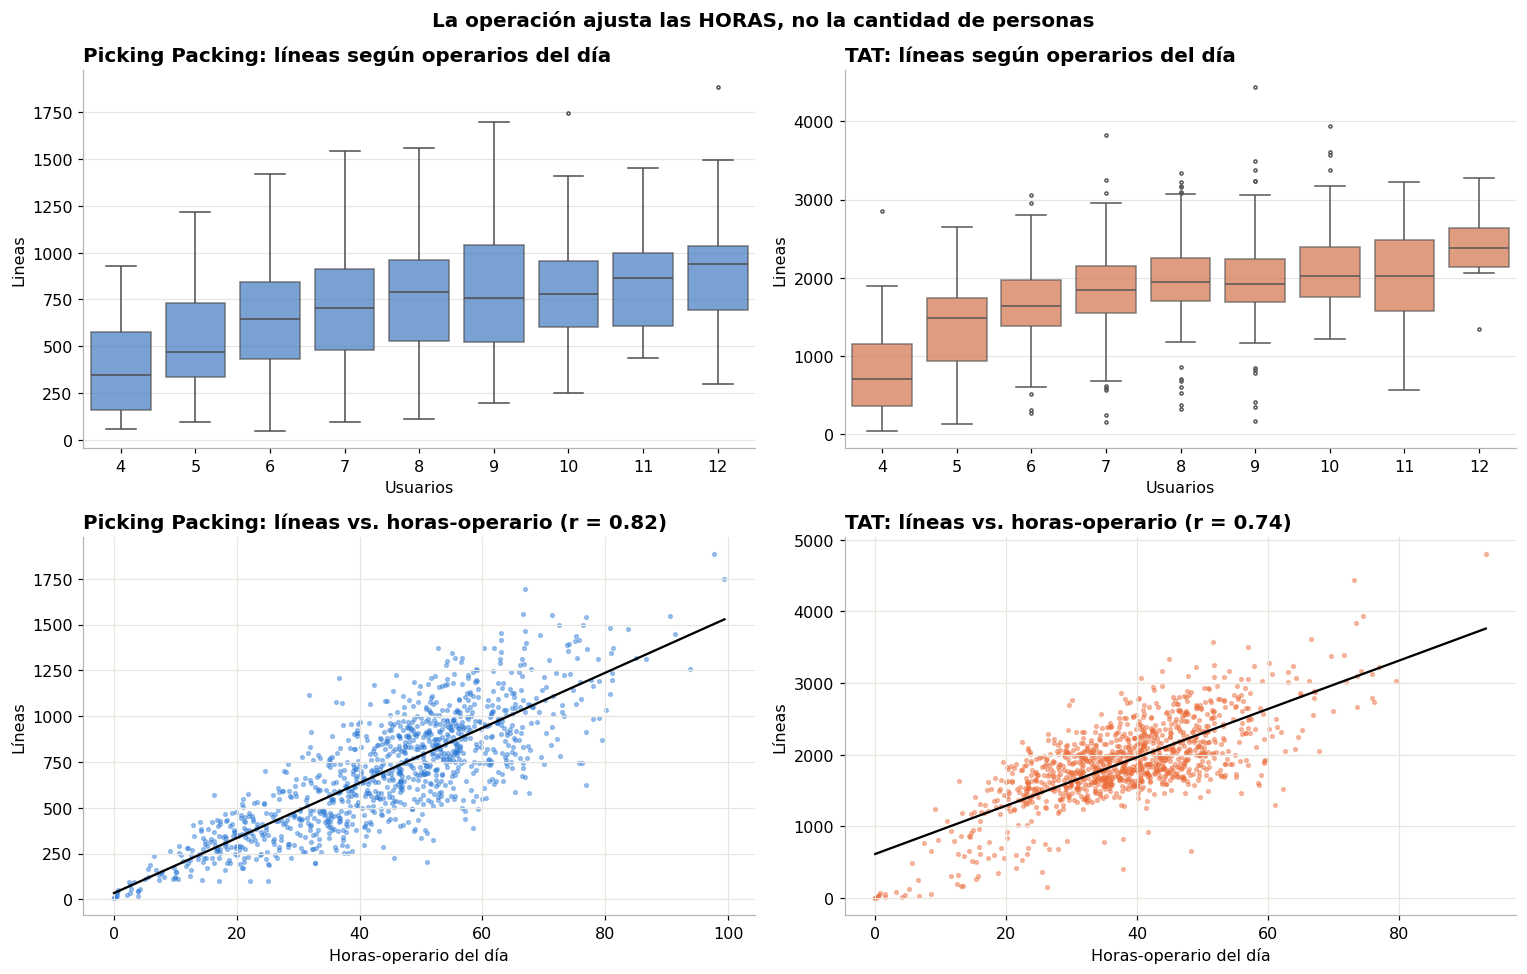

In [54]:
# ============================================
# CELDA 25b: ¿Cómo responde la operación al volumen? Operarios vs. horas
# ============================================
print('CORRELACIÓN DIARIA CON LAS LÍNEAS')
for canal in series:
    x = prod_dia[prod_dia['Canal'] == canal]
    print(f'  {canal:16s} vs operarios: {x["Lineas"].corr(x["Usuarios"]):.2f} | vs horas-operario: {x["Lineas"].corr(x["Horas"]):.2f}')

print('\nMEDIANAS SEGÚN EL NÚMERO DE OPERARIOS DEL DÍA (solo grupos con ≥ 20 días)')
for canal in series:
    x = prod_dia[prod_dia['Canal'] == canal]
    t = (x.groupby('Usuarios').agg(Dias=('Lineas', 'size'), Lineas=('Lineas', 'median'),
                                   Lineas_x_Usuario=('Lineas_x_Usuario', 'median'),
                                   Horas_x_Usuario=('Horas_x_Usuario', 'median'),
                                   Lineas_x_Hora=('Lineas_x_Hora', 'median')))
    print(f'\n{canal}'); print(t[t['Dias'] >= 20].round(1).T.to_string())

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for j, canal in enumerate(series.columns):
    x = prod_dia[prod_dia['Canal'] == canal]
    sns.boxplot(data=x[x['Usuarios'].between(4, 12)], x='Usuarios', y='Lineas', ax=axs[0, j],
                color=COL[canal], fliersize=2, boxprops=dict(alpha=.7))
    axs[0, j].set_title(f'{canal}: líneas según operarios del día', loc='left')
    axs[1, j].scatter(x['Horas'], x['Lineas'], s=6, alpha=.4, color=COL[canal])
    b = np.polyfit(x['Horas'], x['Lineas'], 1)
    xs = np.linspace(0, x['Horas'].max(), 50)
    axs[1, j].plot(xs, np.polyval(b, xs), color='black', lw=1.5)
    axs[1, j].set_title(f'{canal}: líneas vs. horas-operario (r = {x["Lineas"].corr(x["Horas"]):.2f})', loc='left')
    axs[1, j].set_xlabel('Horas-operario del día'); axs[1, j].set_ylabel('Líneas')
fig.suptitle('La operación ajusta las HORAS, no la cantidad de personas', fontweight='bold', fontsize=13)
guardar('25_recursos_vs_volumen'); plt.show()

In [55]:
# ============================================
# CELDA 25c: Capacidad necesaria según la demanda (régimen actual)
# ============================================
actual = prod_dia[prod_dia['Tramo'] == 'Jornada 42 h']

# Parámetros de referencia del régimen actual (medianas)
ref = actual.groupby('Canal').agg(Lineas_x_Hora=('Lineas_x_Hora', 'median'),
                                  Horas_x_Usuario=('Horas_x_Usuario', 'median'))
ref['Lineas_x_Operario'] = ref['Lineas_x_Hora'] * ref['Horas_x_Usuario']
print('PARÁMETROS DE REFERENCIA (jornada 42 h, medianas):'); print(ref.round(1).to_string())

def operarios_necesarios(lineas, canal):
    return np.ceil(lineas / ref.loc[canal, 'Lineas_x_Operario'])   # se redondea hacia arriba

# 1. Por día de la semana: asignados vs. necesarios (con 1 decimal, para ver la brecha real)
print('\nASIGNADOS vs. NECESARIOS POR DÍA DE LA SEMANA (jornada 42 h, medianas)')
print('Necesarios = operarios para que cada uno tenga la carga típica del régimen actual')
for canal in series:
    x = actual[actual['Canal'] == canal].copy()
    x['Necesarios'] = x['Lineas'] / ref.loc[canal, 'Lineas_x_Operario']
    t = x.groupby('Dia', observed=True).agg(Lineas=('Lineas', 'median'), Asignados=('Usuarios', 'median'),
                                            Necesarios=('Necesarios', 'median'))
    t['Brecha'] = t['Asignados'] - t['Necesarios']
    print(f'\n{canal}'); print(t.round(1).to_string())

# 2. Variación de la carga por operario con la plantilla actual
print('\nCARGA POR OPERARIO (líneas por operario por día, jornada 42 h)')
for canal in series:
    lu = actual[actual['Canal'] == canal]['Lineas_x_Usuario']
    p10, p50, p90 = lu.quantile([.1, .5, .9])
    print(f'  {canal:16s} P10: {p10:5.0f} | mediana: {p50:5.0f} | P90: {p90:5.0f}  → el día más cargado (P90) '
          f'pide {p90 / p10:.1f} veces el trabajo por persona del día más liviano (P10)')

# 3. Tabla de planeación: operarios necesarios según el volumen pronosticado
print('\nTABLA DE PLANEACIÓN: operarios necesarios según las líneas pronosticadas')
for canal, rango in [('Picking Packing', range(400, 1301, 100)), ('TAT', range(800, 2601, 200))]:
    print(f'  {canal}: ' + ' | '.join(f'{l:,} → {int(operarios_necesarios(l, canal))}' for l in rango))

PARÁMETROS DE REFERENCIA (jornada 42 h, medianas):
                 Lineas_x_Hora  Horas_x_Usuario  Lineas_x_Operario
Canal                                                             
Picking Packing           14.4              7.3              105.7
TAT                       59.8              4.2              249.3

ASIGNADOS vs. NECESARIOS POR DÍA DE LA SEMANA (jornada 42 h, medianas)
Necesarios = operarios para que cada uno tenga la carga típica del régimen actual

Picking Packing
           Lineas  Asignados  Necesarios  Brecha
Dia                                             
Lunes       743.0        7.0         7.0    -0.0
Martes      660.5        7.0         6.2     0.8
Miércoles   820.0        7.0         7.8    -0.8
Jueves      903.0        7.0         8.5    -1.5
Viernes     750.0        8.0         7.1     0.9

TAT
           Lineas  Asignados  Necesarios  Brecha
Dia                                             
Lunes      1527.0        6.0         6.1    -0.1
Martes     1484

### Conclusiones: capacidad y recursos

**1. La operación ajusta las horas, no las personas**

| | Picking Packing | TAT |
|---|---|---|
| Correlación líneas vs. operarios | 0.35 | 0.41 |
| Correlación líneas vs. horas-operario | **0.82** | **0.74** |

Ante un día de mayor volumen, el mismo equipo dedica más horas al picking. La **velocidad por hora es casi constante** sin importar cuántas personas haya (PP 15-17 líneas/h; TAT 47-59 líneas/h): por eso es una base confiable para planear.

**2. Rendimientos decrecientes al agregar personal**
- PP: con 8 operarios se sacan 787 líneas; con 10, 782. Cada operario adicional reduce las horas de los demás (6.7 → 5.2 h) en lugar de aumentar el volumen.
- TAT: de 8 a 11 operarios, las líneas por persona bajan de 243 a 184.
- Sugiere un **techo operativo de ≈8 operarios por canal** (posibles cuellos de botella: llegada de pedidos o espacio en bodega). *Hipótesis por validar.*

**3. Parámetros de capacidad (régimen actual, jornada 42 h)**

| | Líneas/hora por operario | Horas activas por operario | **Capacidad por operario/día** |
|---|---|---|---|
| Picking Packing | 14.4 | 7.3 | **≈106 líneas** |
| TAT | 59.8 | 4.2 | **≈249 líneas** |

> **Operarios necesarios = Líneas pronosticadas ÷ capacidad por operario** (redondeado hacia arriba)

**Tabla de planeación:**
- **PP:** 600 líneas → 6 · 700 → 7 · 800 → 8 · 900 → 9 · 1,000 → 10
- **TAT:** 1,200 líneas → 5 · 1,400 → 6 · 1,600 → 7 · 1,800 → 8 · 2,000 → 9

**4. Distribución actual de la plantilla por día de la semana**

| PP (mediana) | Lun | Mar | Mié | Jue | Vie |
|---|---|---|---|---|---|
| Asignados | 7 | 7 | 7 | 7 | 8 |
| Necesarios | 7.0 | 6.2 | 7.8 | **8.5** | 7.1 |
| Brecha | 0 | +0.8 | −0.8 | **−1.5** | +0.9 |

- **TAT está bien dimensionado** (6 operarios; brecha ≤ 0.5 todos los días).
- **PP:** al jueves le falta ≈1.5 operarios y al miércoles ≈0.8; al martes y viernes les sobra ≈0.8-0.9. **Reasignar un operario del martes/viernes al miércoles/jueves** equilibra la semana **sin aumentar la plantilla**.

**5. El desajuste grande está en días específicos, no en el día de la semana**

| Líneas por operario/día (jornada 42 h) | P10 | Mediana | P90 | P90 / P10 |
|---|---|---|---|---|
| Picking Packing | 66 | 107 | 161 | **2.4×** |
| TAT | 154 | 244 | 325 | **2.1×** |

Con la plantilla actual, en los días más pesados cada operario hace **más del doble** de trabajo que en los más livianos. Esos picos vienen de rutas, festivos y temporadas, y hoy se absorben con más horas sobre la marcha.

**Valor del modelo:** anticipar esos días con una semana de antelación permite **planear** la capacidad (turnos, horas, apoyo entre canales) en lugar de reaccionar.

⚠️ *Limitaciones:* las horas activas son el tiempo entre la primera y la última línea (incluyen pausas). TAT registra pocas horas activas por operario (4.2 h), lo que sugiere que su personal hace otras tareas además del picking. Los parámetros del régimen actual se basan en 87 días.

# PARTE 4 — Cierre del EDA

## 24. Revisión de data leakage

**Pregunta para cada variable:** en el **corte** (último día operativo de la semana, en la noche), ¿se conoce su valor para **cada día** de la semana siguiente?

### Variables del dataset original

| Variable | ¿Se conoce en el corte? | Decisión | Razón |
|---|---|---|---|
| `Fecha` | ✅ Sí | **Usar** (para derivar el calendario) | El calendario se conoce siempre |
| `Canal` | ✅ Sí | **Usar** (un modelo por canal) | Segmentación |
| `Ciudad` | ⚠️ Depende | **Usar como ciudades programadas** | Solo si la programación de rutas se conoce antes; si no, usar la frecuencia histórica ciudad × día |
| `Lineas` | — | **Variable objetivo** | Solo sus **rezagos ≥ 7 días** pueden ser features |
| `Dia_Semana`, `Dia_Semana_Num`, `Dia_Mes`, `Semana_Anio`, `Mes` | ✅ Sí | **Usar** | Calendario |
| `Anio` | ✅ Sí | ⚠️ **No como tendencia lineal** | La tendencia tiene escalones, no es una recta (secciones 13 y 17) |
| `Cantidad` | ❌ No | **Descartar** | Se conoce después de pickear y cambió de unidad en mar-2025 |
| `Puntos_Envio_Distintos` | ❌ No | **Descartar** | Resultado del día (mismos pedidos que generan las líneas) |
| `SKUs_Distintos`, `Ubicaciones_Visitadas` | ❌ No | **Descartar** | Resultado del picking del día |
| `Pedidos_Distintos`, `Ruteos_Distintos` | ❌ No | **Descartar** | Se conocen con el picking del día (además no son sumables entre ciudades) |
| `Usuarios_Picking` | ❌ No | **Descartar** | Es **capacidad**, no demanda: se usa **después** del pronóstico para planear (sección 23). Usarla sería circular |
| `Cantidad_Promedio/Max/Min_Linea` | ❌ No | **Descartar** | Resultado del día + cambio de unidad |

### Variables derivadas (candidatas para el modelo)

| Variable | ¿Se conoce en el corte? | Decisión |
|---|---|---|
| Día de la semana, mes, semana del año | ✅ | **Usar** |
| Festivos: `dias_operativos_semana`, `dia_antes_festivo`, `dia_despues_festivo` | ✅ (calendario) | **Usar** |
| `semana_santa`, `semana_post_semana_santa`, `fin_de_anio` | ✅ (calendario) | **Usar** |
| Régimen: `expansion_tat_2024`, `catalogo_2026`, `recorte_rutas_tat`, `jornada_42h` | ✅ (decisiones vigentes) | **Usar** |
| `lag_7`, `lag_14`, `lag_21`, `lag_28`, `prom_4_semanas`, `lag_364` | ✅ (ya ocurrieron) | **Usar** |
| `nivel_reciente` (promedio de los últimos 5-10 días operativos antes del corte) | ✅ | **Usar** (reemplaza lag 1-2) |
| `lag_1`, `lag_2` (días inmediatamente anteriores) | ❌ No para todo el horizonte | **Descartar** |
| Horas-operario, operarios del día (dataset de productividad) | ❌ No | **Descartar como feature**: se usan para convertir el pronóstico en personal |
| Pedidos ya cargados en el WMS antes del día | ⚠️ Solo si existen antes del día | **Mejora futura**: sería el mejor regresor si el WMS los tiene con anticipación |

### Conclusiones: data leakage

- Las variables operativas del mismo día (**puntos de envío, pedidos, SKUs, ubicaciones, ruteos, operarios, horas y cantidades**) explican muy bien el volumen (correlaciones de hasta 0.99 con las líneas, sección 11), pero **solo se conocen después de que ocurre el picking**. Usarlas haría que el modelo pareciera mucho más preciso de lo que realmente es en la operación.
- **Regla aplicada en todo el proyecto:** solo entran al modelo variables de **calendario**, de **régimen** (decisiones de negocio vigentes) y **rezagos de las líneas de al menos 7 días**, porque son las únicas disponibles en el corte para todo el horizonte de pronóstico.
- Los datos de operarios y horas **no se usan para predecir la demanda**: se usan **después** del pronóstico para convertirlo en personal necesario (sección 23).
- El efecto de usar variables del mismo día se cuantifica en el **Experimento 0** del modelado.